In [2]:
import torch
import shutup
shutup.please()
import neck
import numpy as np
from pathlib import Path
neckruns = Path('/opt/dlami/nvme/neckruns')

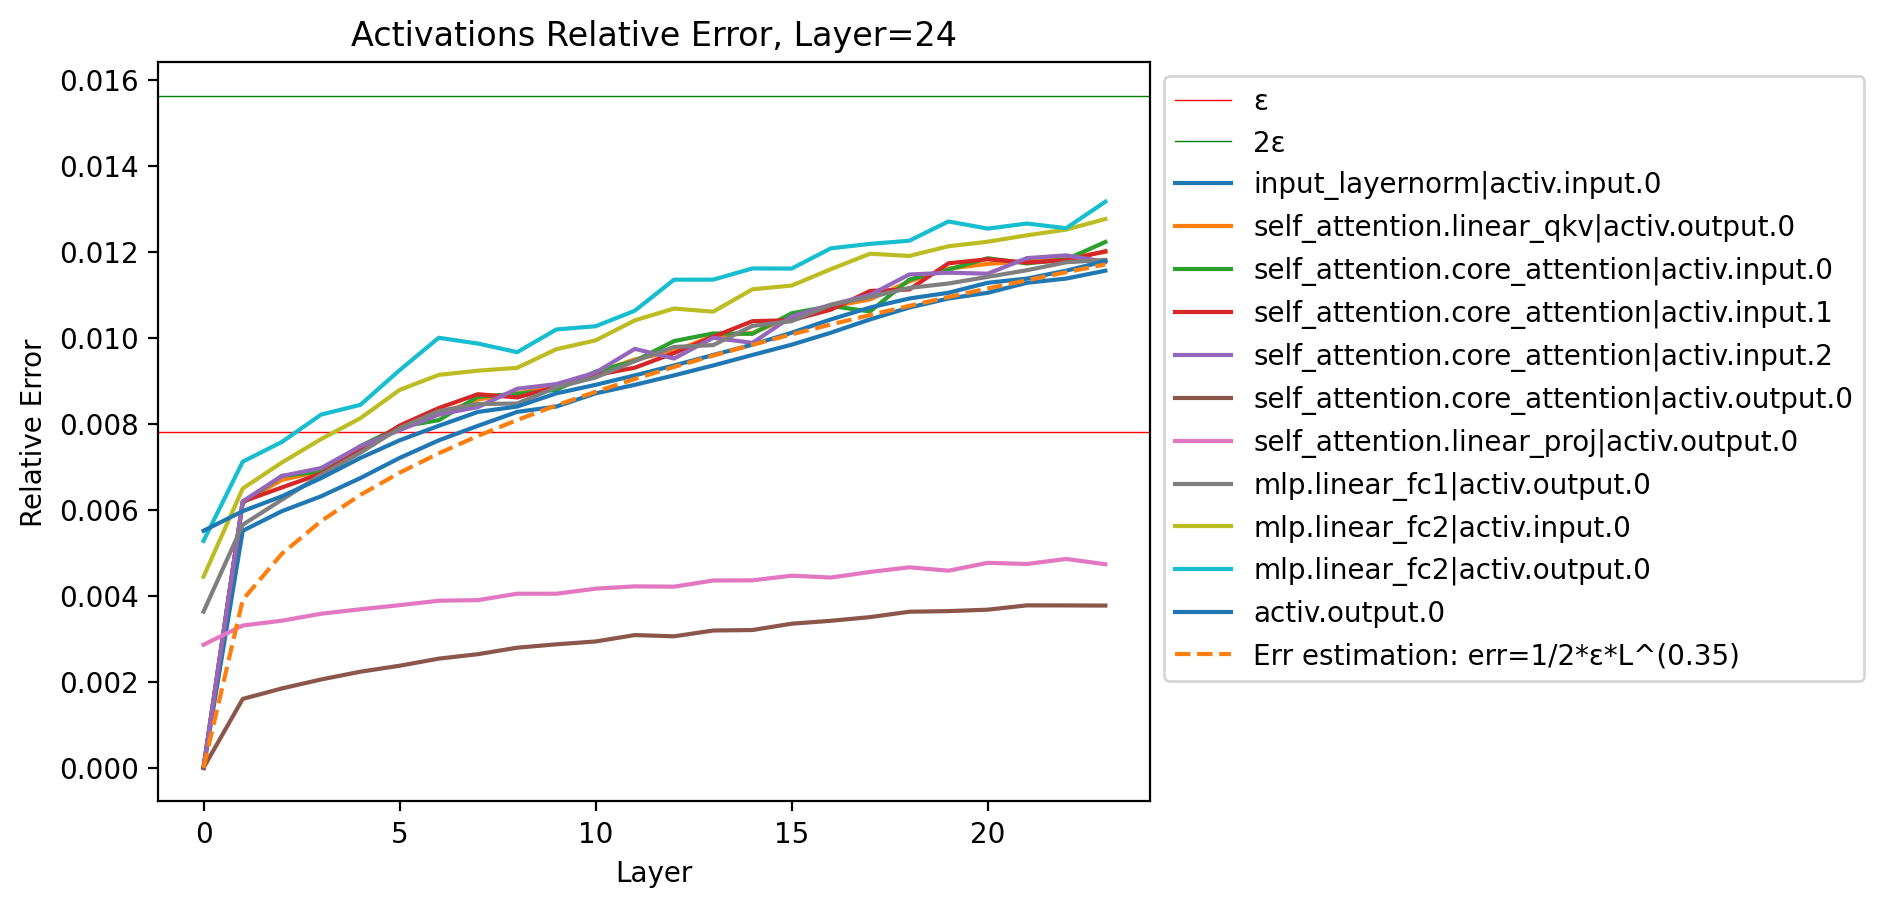

In [3]:
l = 24
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}/activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
label = "Err estimation: err=1/2*ε*L^(0.35)"
plt.plot(range(l), np.maximum(1/2*(bf16)*np.arange(l)**(0.35), 0), label=label, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activations Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()

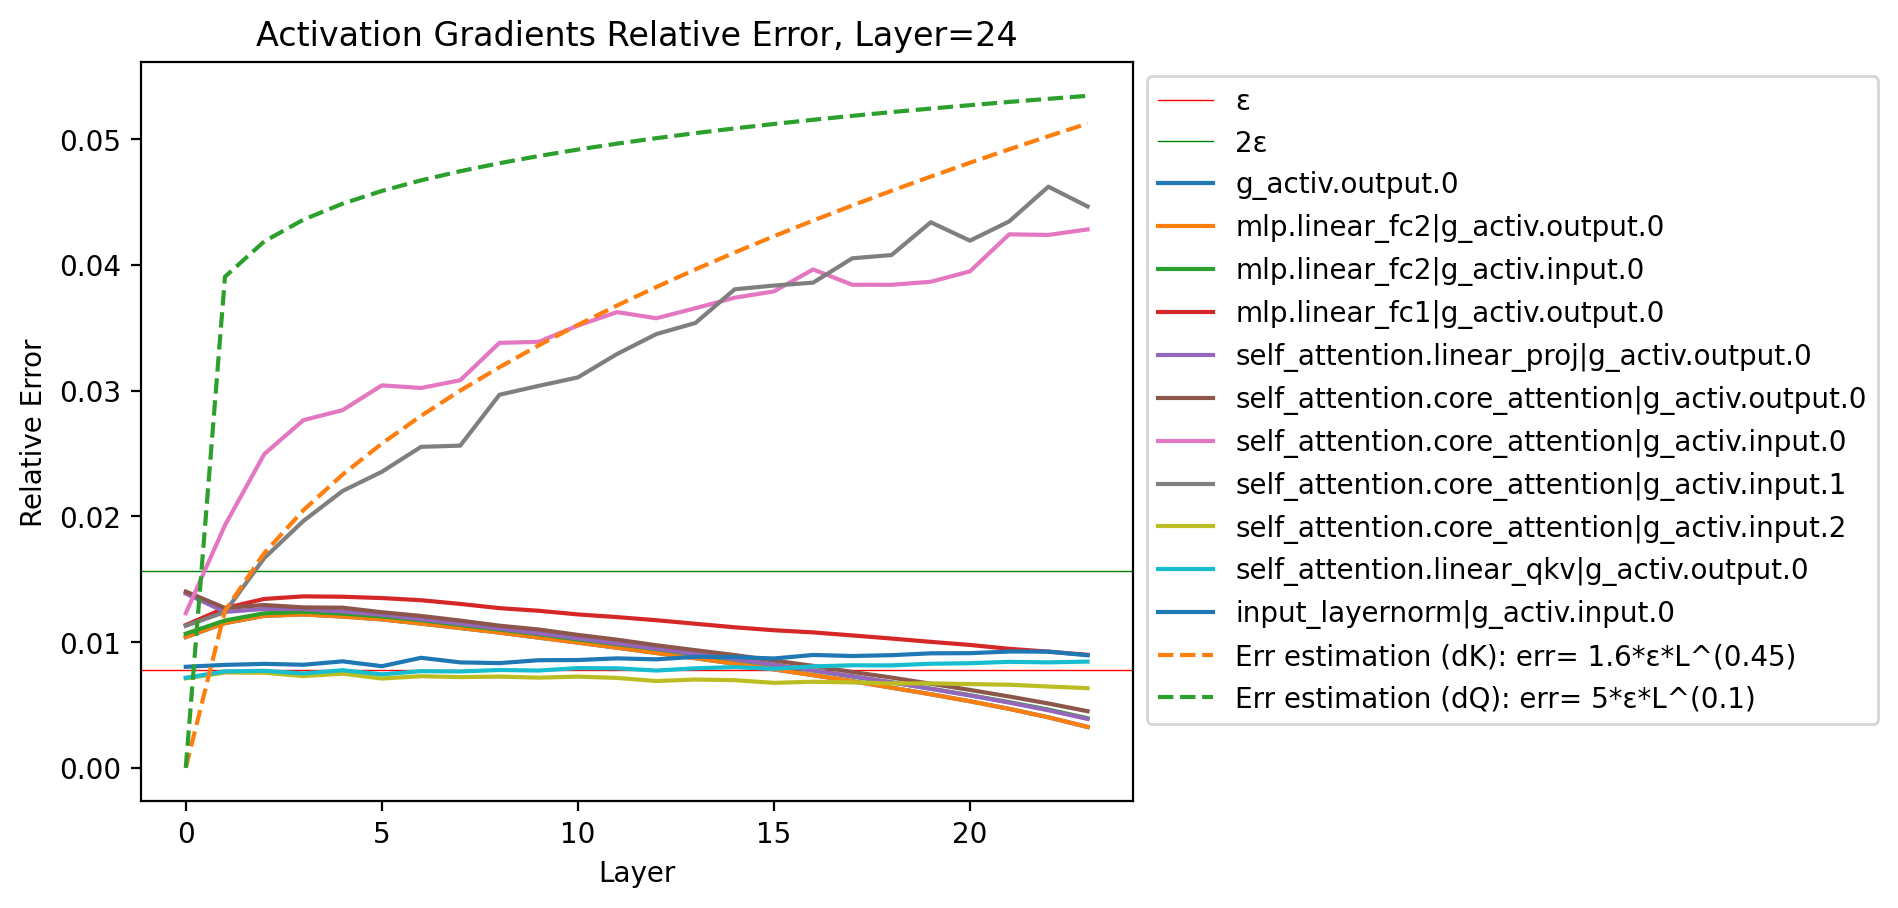

In [4]:
l = 24
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"eval-err-tp/_single-v-tp2--L{l}/g_activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
labelK = "Err estimation (dK): err= 1.6*ε*L^(0.45)"
labelQ = "Err estimation (dQ): err= 5*ε*L^(0.1)"
plt.plot(range(l), 1.6*bf16*np.arange(l)**(0.45), label=labelK, linestyle='--')
plt.plot(range(l), 5*bf16*np.arange(l)**(0.1), label=labelQ, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activation Gradients Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()

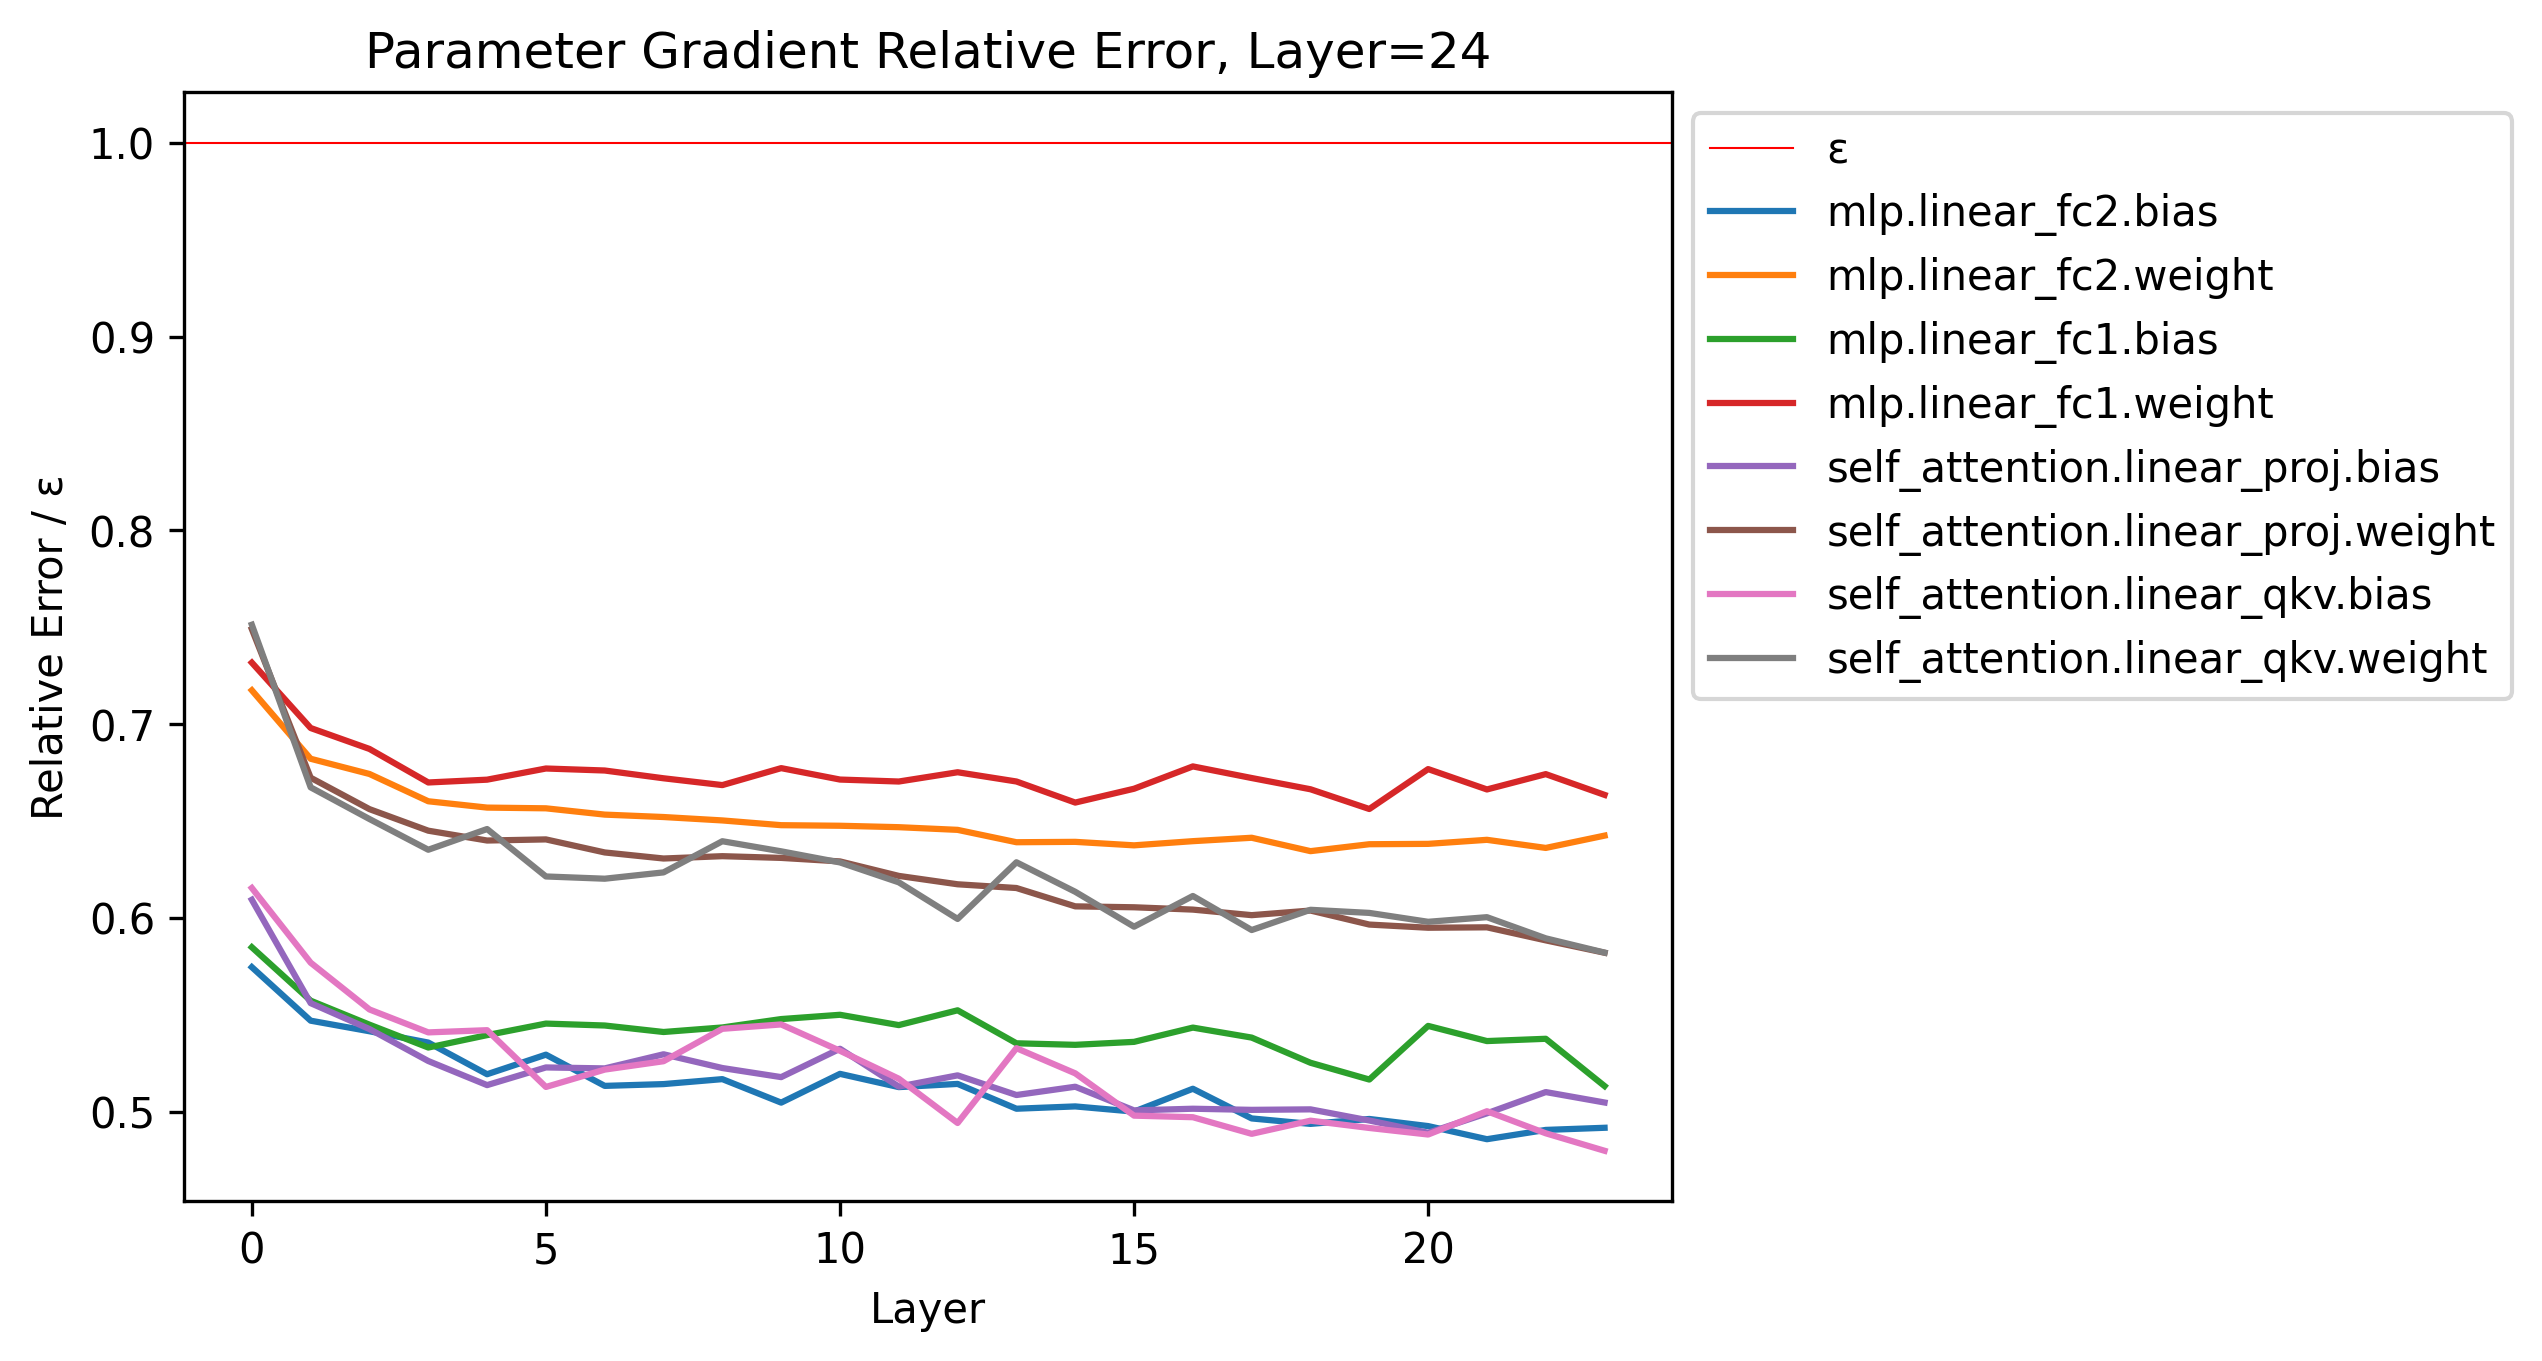

In [ ]:
err_arr = neck.inspector.get_err_array(torch.load(neckruns/"_single-v-tp2--l24-te/g_param.pt"), 4, 24)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=1, color='r', linestyle='-', linewidth=0.5, label='ε')
for k, rerr in err_arr.items():
    plt.plot(range(24), rerr.mean(axis=0)/bf16, label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title("Parameter Gradient Relative Error, Layer=24")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

In [13]:
import re
import numpy as np
from collections import defaultdict
def parse_main(name):
    pattern = r".*?layers\.(\d+)[\|\.](\S+)"
    m = re.match(pattern, name)
    if m:
        layer_num = m.group(1)
        activation_name = m.group(2)
        return layer_num, activation_name
    else:
        return None, None

def get_err_array_main(err_dict, layer_num) -> dict[str, np.ndarray]:
    err_array_dict = defaultdict(lambda: np.zeros((layer_num,)))
    for name, err in err_dict.items():
        layer, activation_name = parse_main(name)
        if layer is None:
            continue
        err_array_dict[activation_name][int(layer)] = err
    return err_array_dict

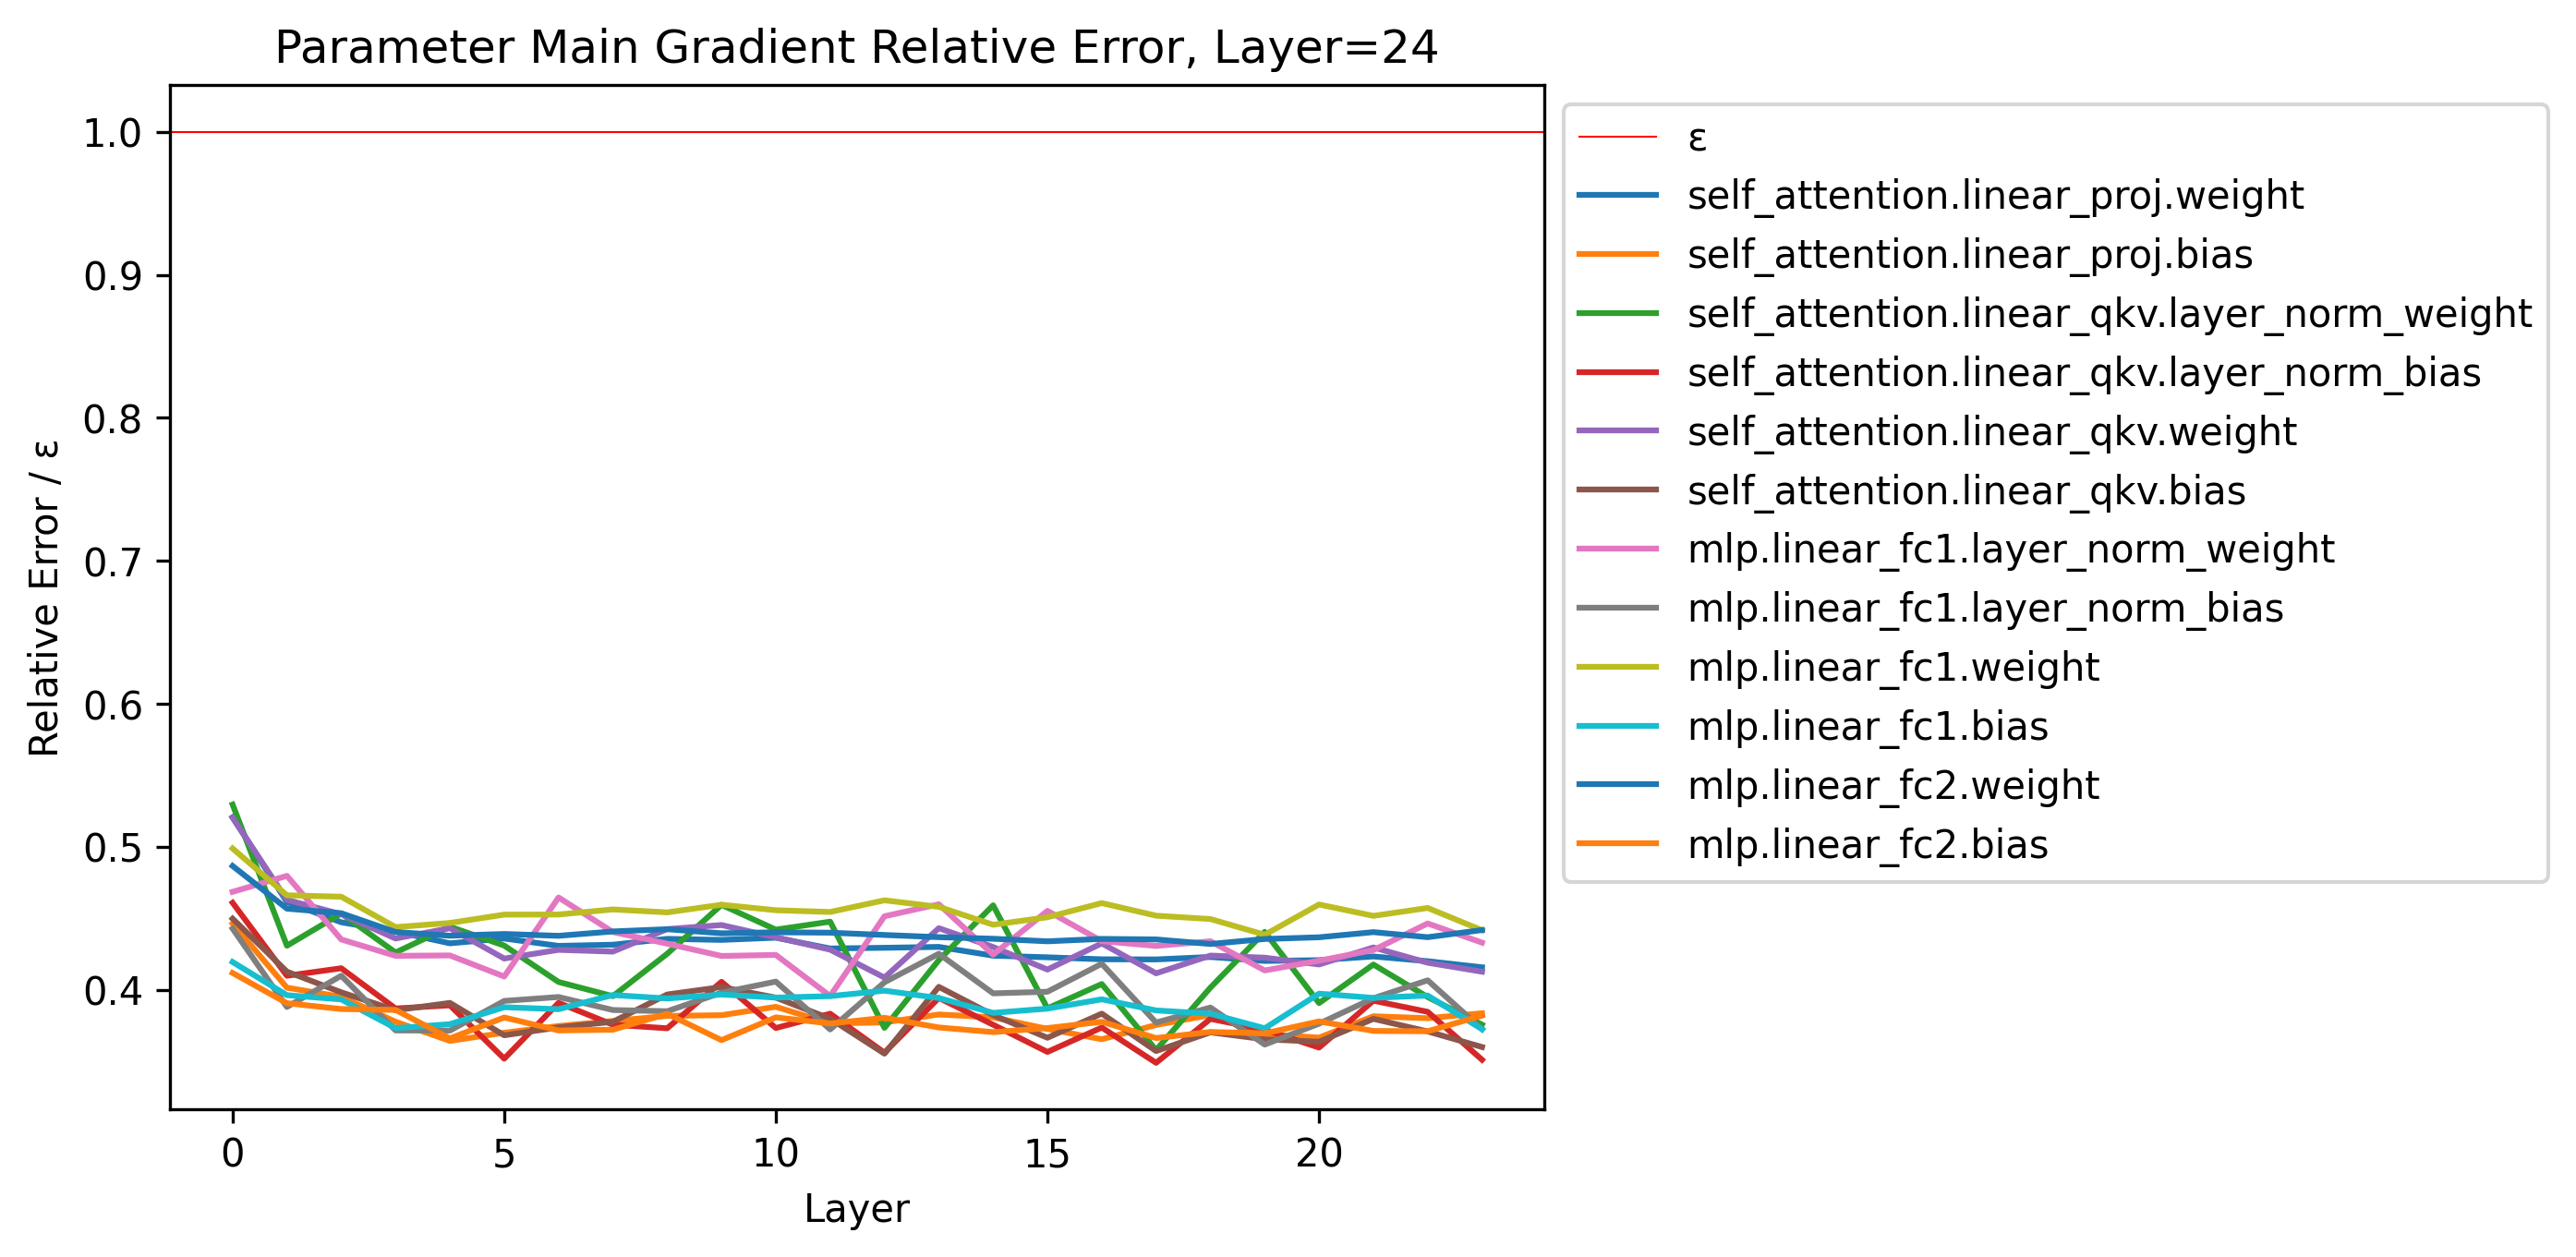

In [ ]:
num_layer = 24
err_arr = get_err_array_main(torch.load(neckruns/"_single-v-tp2--l24-te/g_param_main.pt"), num_layer)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=1, color='r', linestyle='-', linewidth=0.5, label='ε')
for k, rerr in err_arr.items():
    plt.plot(range(num_layer), rerr/bf16, label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title("Parameter Main Gradient Relative Error, Layer=24")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

# L=48

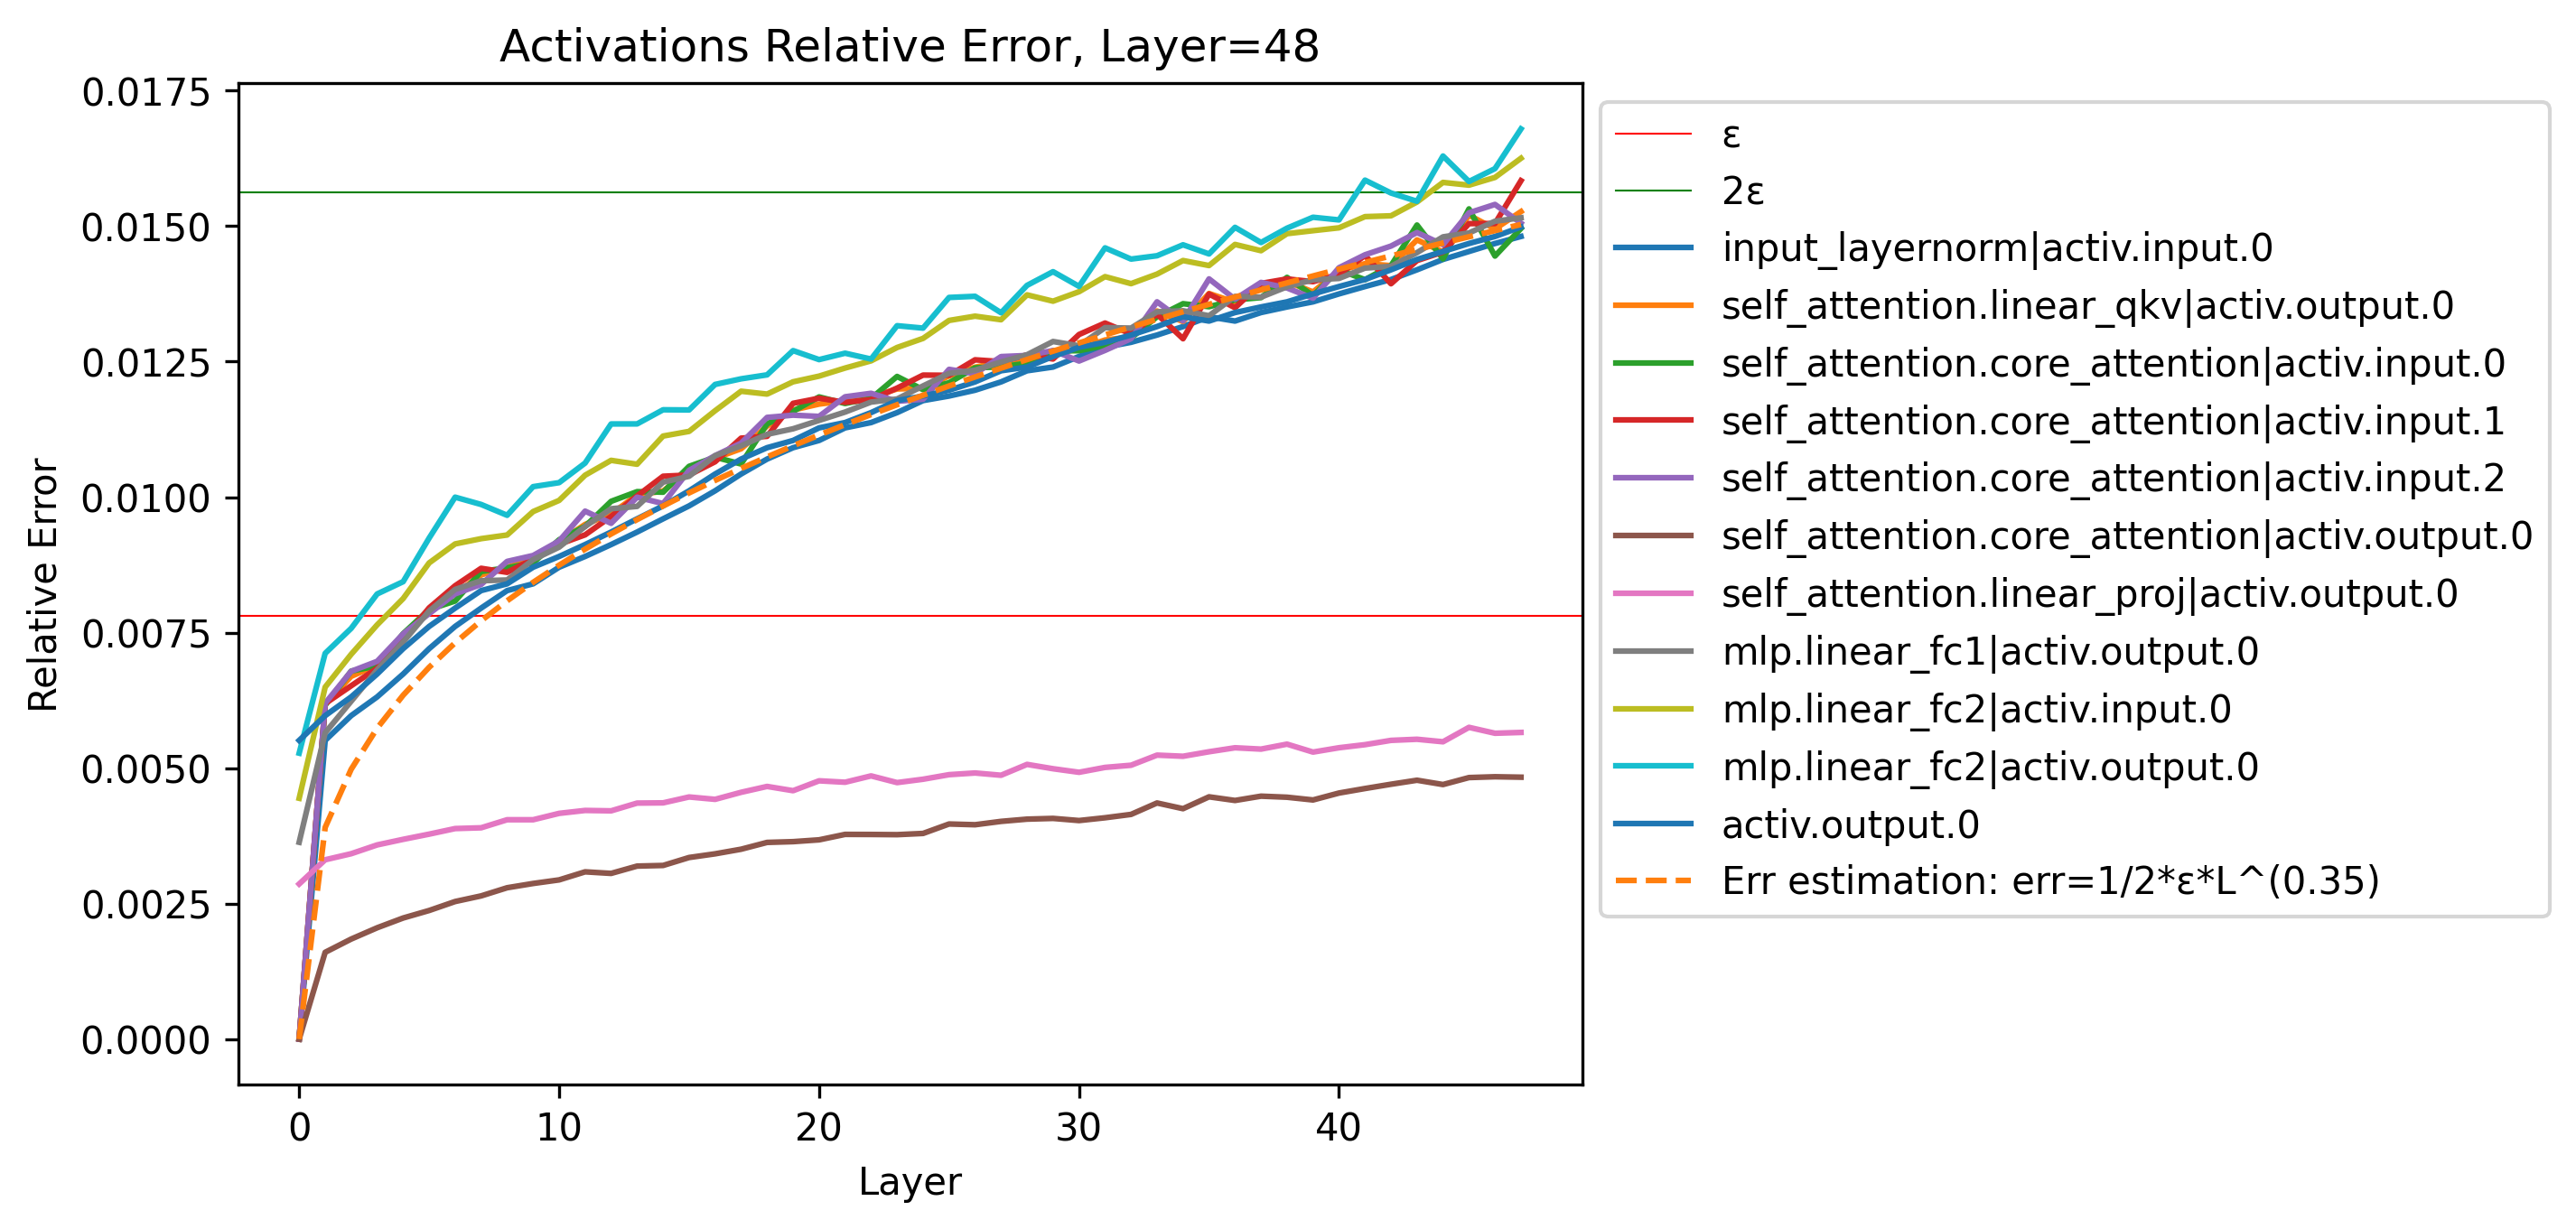

In [ ]:
l = 48
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}-te/activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
label = "Err estimation: err=1/2*ε*L^(0.35)"
plt.plot(range(l), np.maximum(1/2*(bf16)*np.arange(l)**(0.35), 0), label=label, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activations Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()

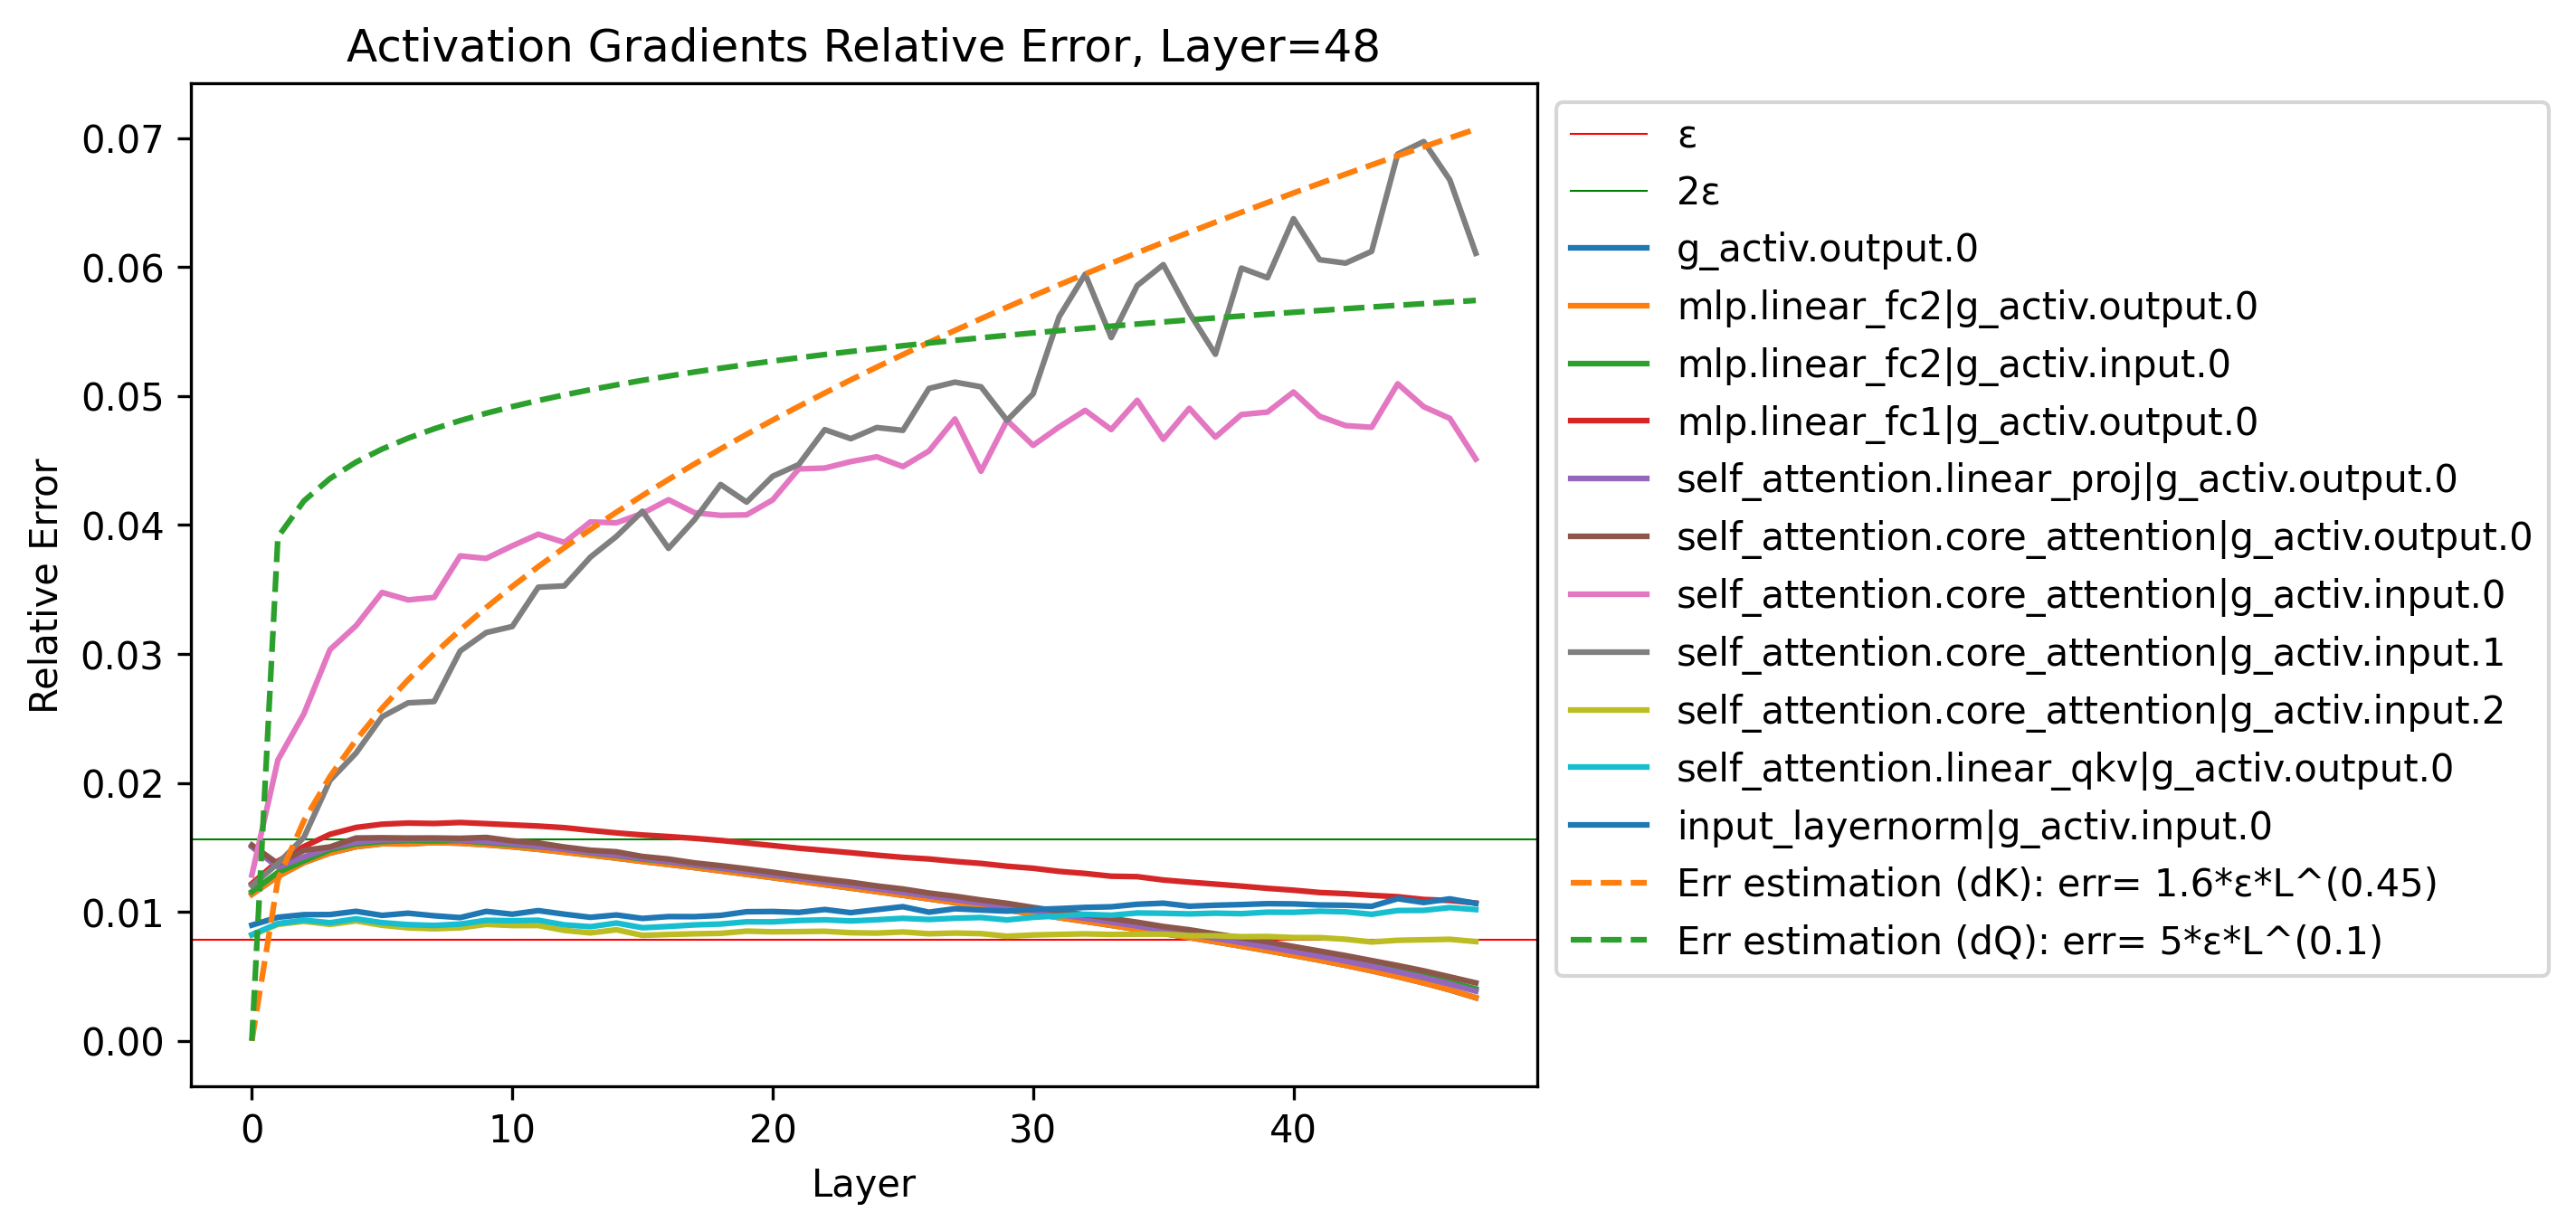

In [ ]:
l = 48
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}-te/g_activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
labelK = "Err estimation (dK): err= 1.6*ε*L^(0.45)"
labelQ = "Err estimation (dQ): err= 5*ε*L^(0.1)"
plt.plot(range(l), 1.6*bf16*np.arange(l)**(0.45), label=labelK, linestyle='--')
plt.plot(range(l), 5*bf16*np.arange(l)**(0.1), label=labelQ, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activation Gradients Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()

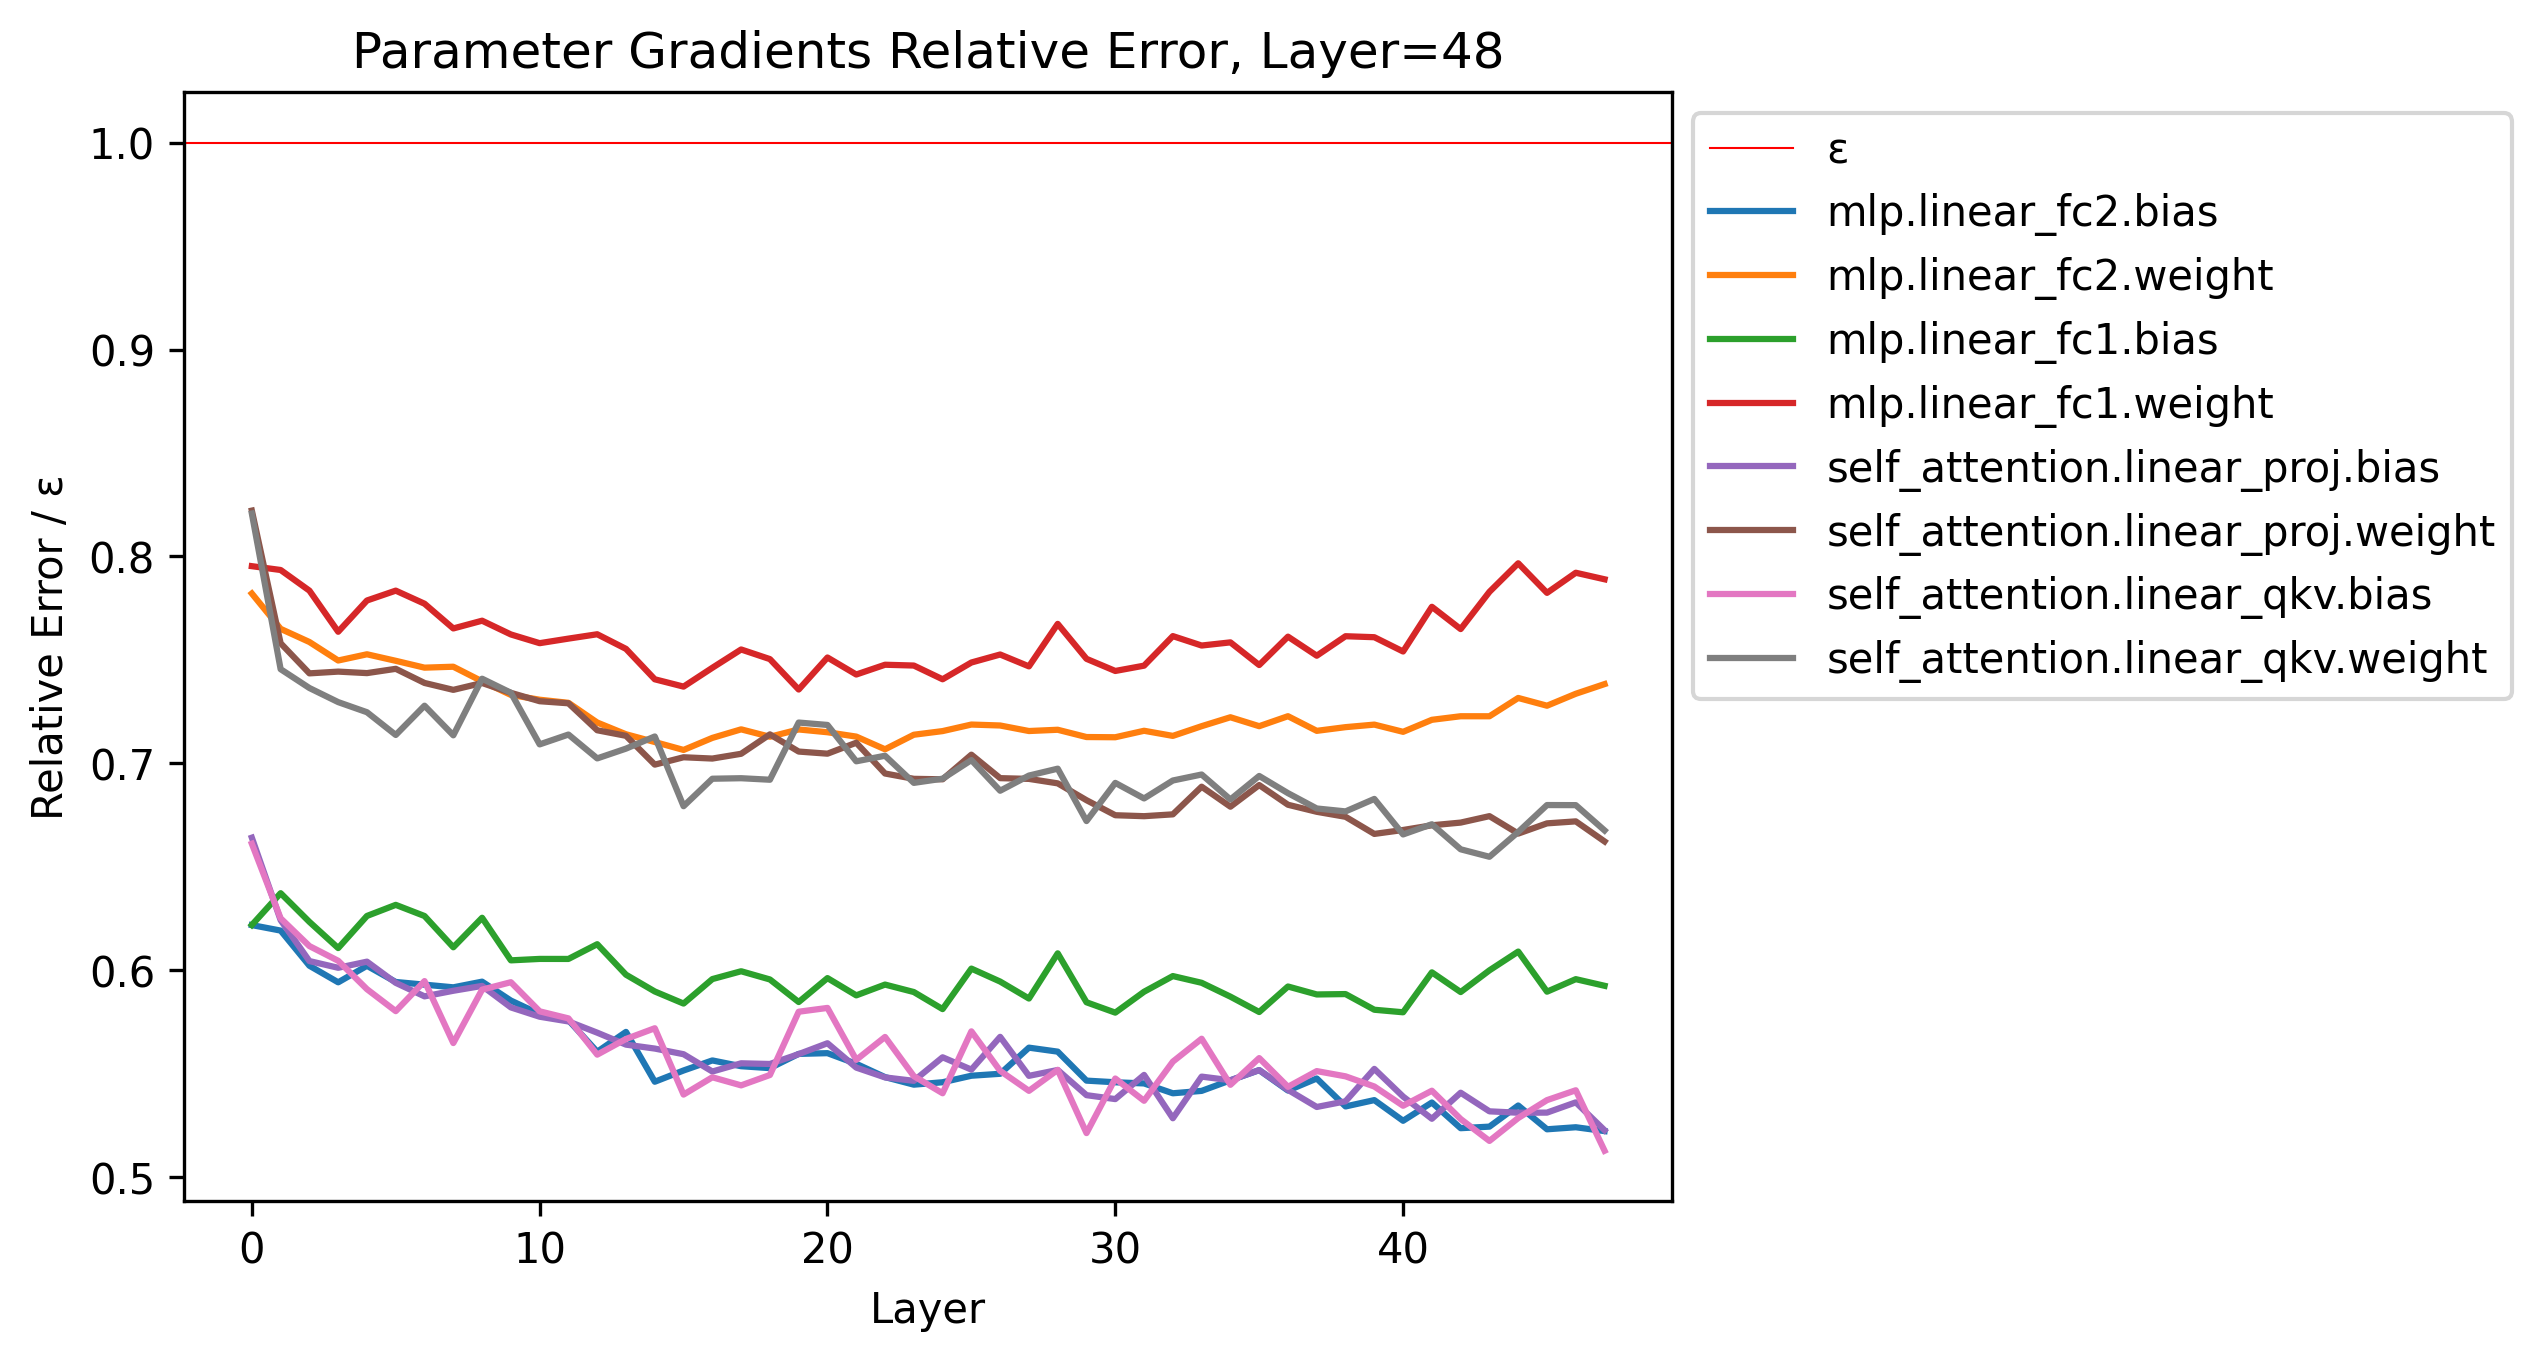

In [ ]:
err_arr = neck.inspector.get_err_array(torch.load(neckruns/"_single-v-tp2--l48-te/g_param.pt"), 4, 48)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=1, color='r', linestyle='-', linewidth=0.5, label='ε')
for k, rerr in err_arr.items():
    plt.plot(range(48), rerr.mean(axis=0)/bf16, label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title("Parameter Gradients Relative Error, Layer=48")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

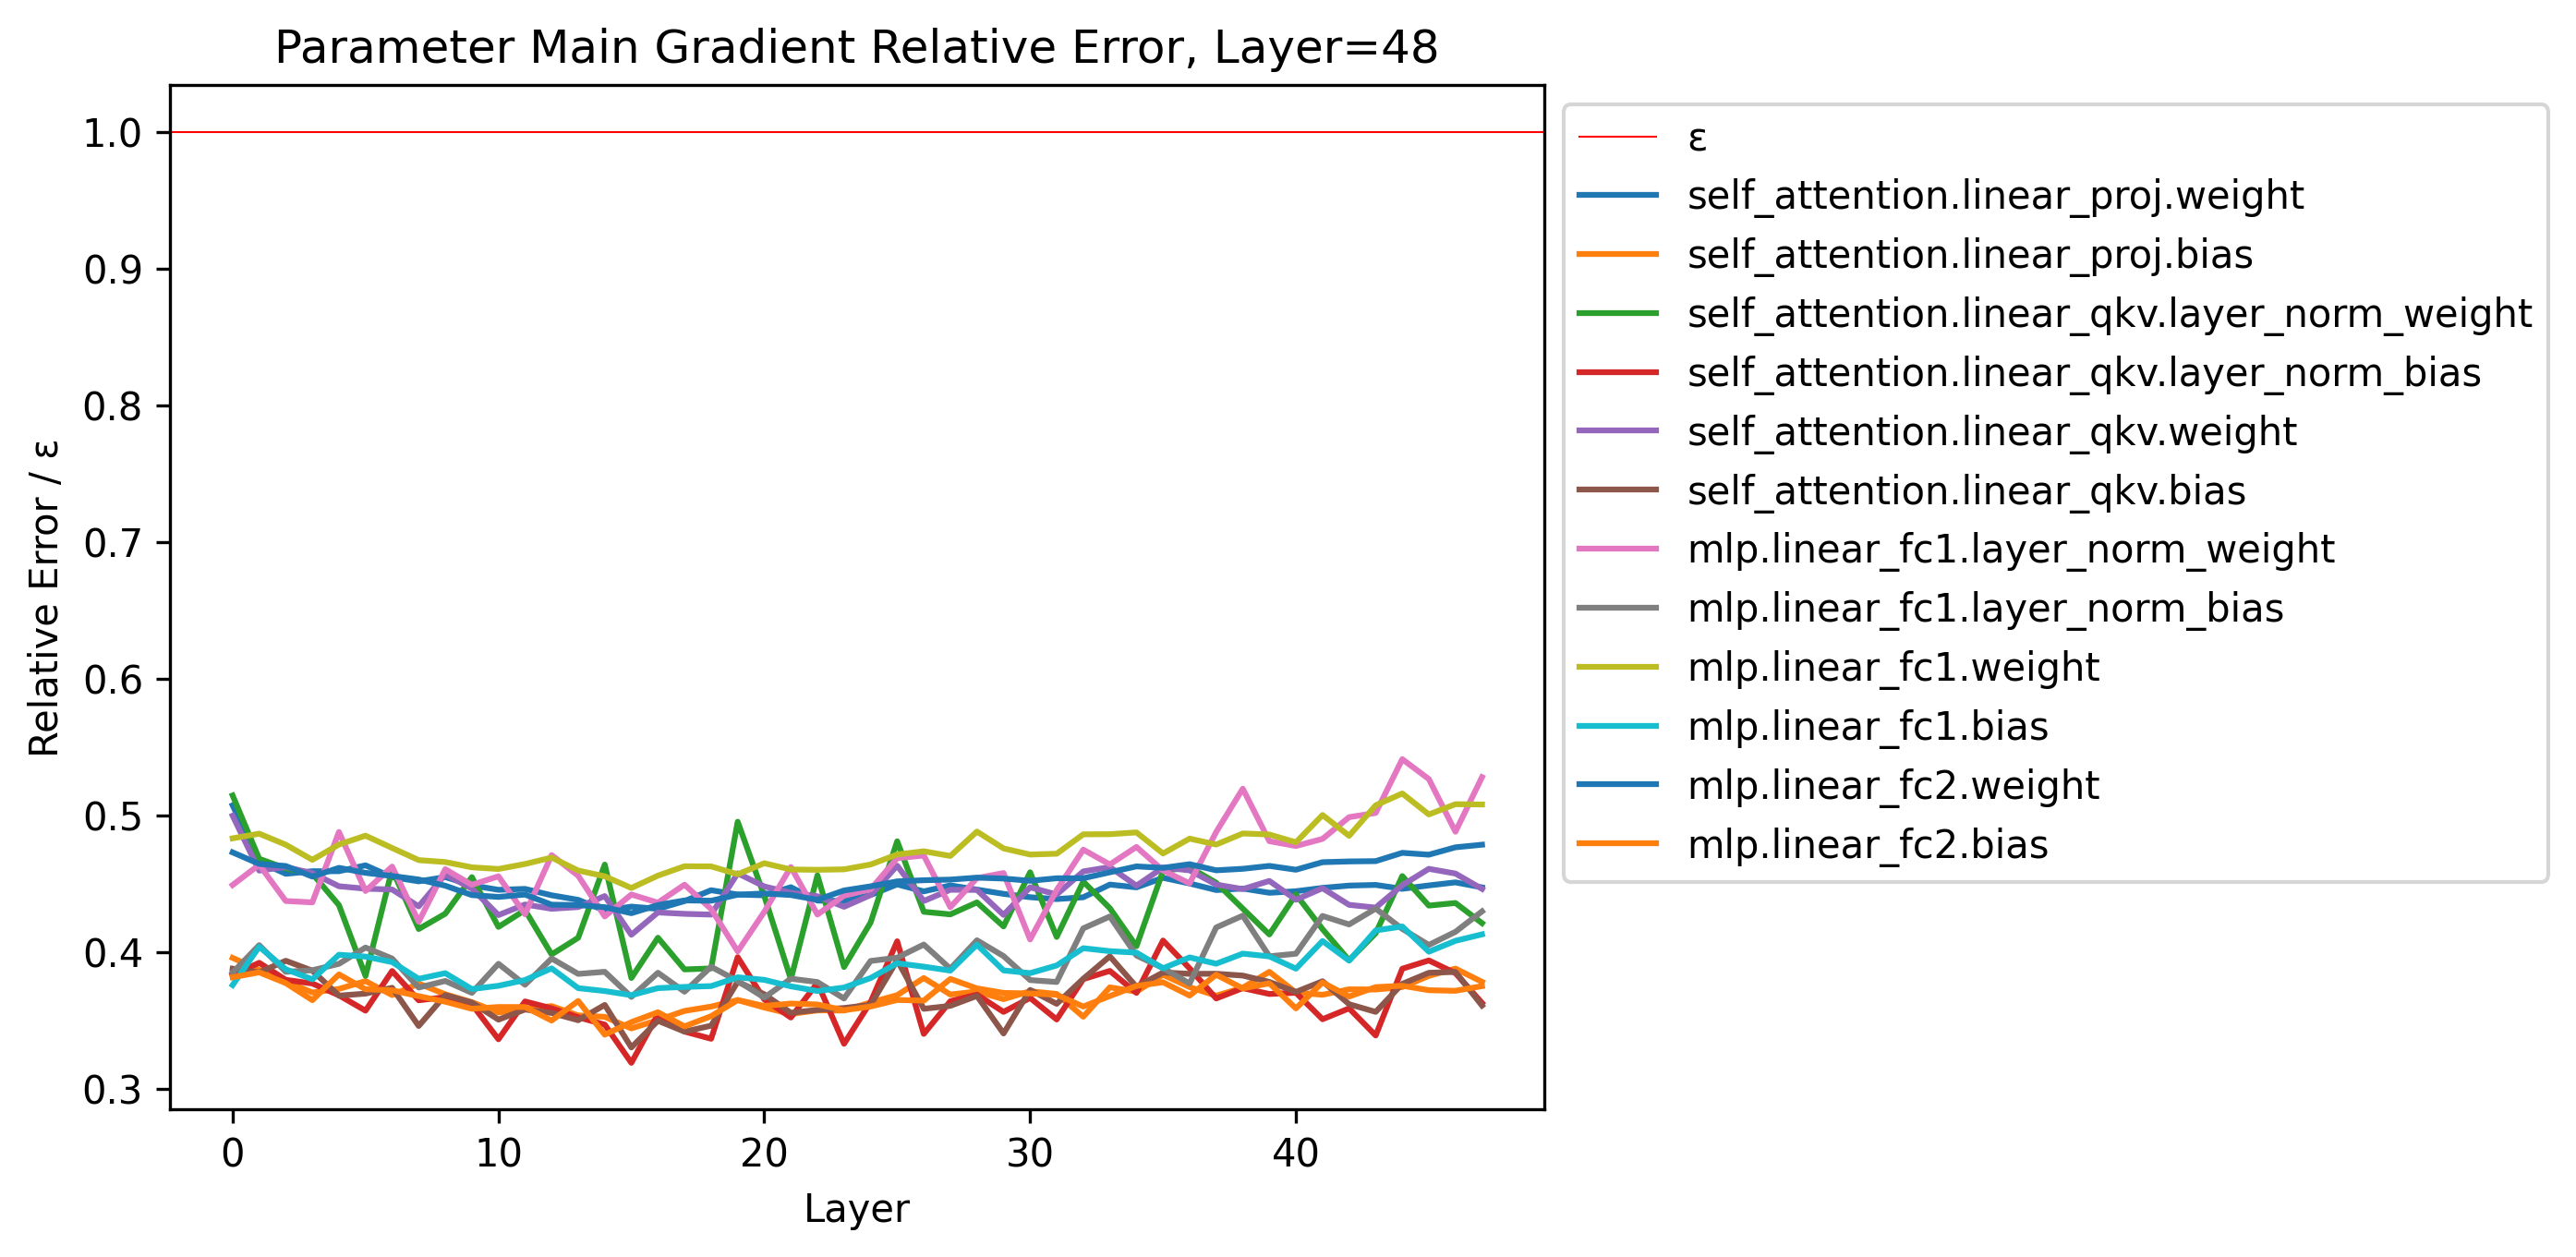

In [ ]:
num_layer = 48
err_arr = get_err_array_main(torch.load(neckruns/"_single-v-tp2--l48-te/g_param_main.pt"), num_layer)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=1, color='r', linestyle='-', linewidth=0.5, label='ε')
for k, rerr in err_arr.items():
    plt.plot(range(num_layer), rerr/bf16, label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title("Parameter Main Gradient Relative Error, Layer=48")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

0.3105612931127131 -5.589044962697518


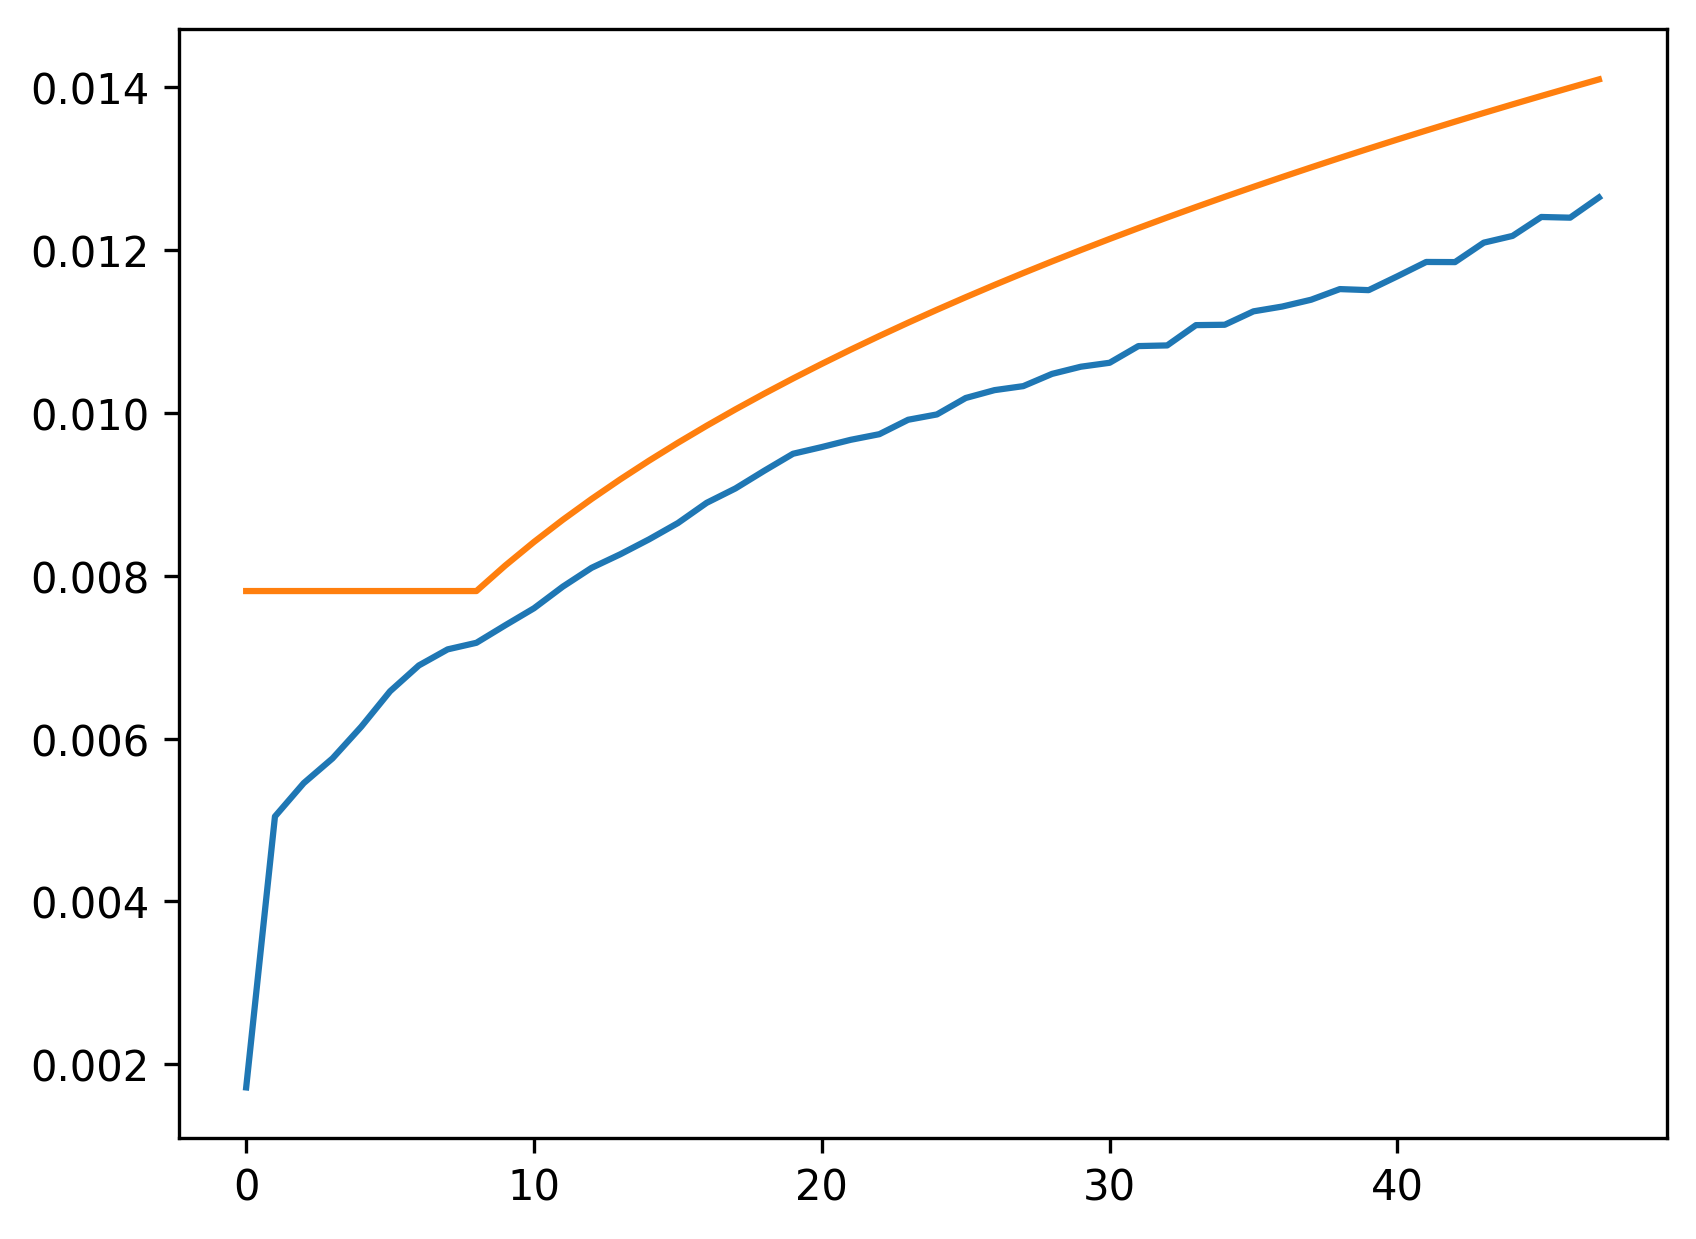

In [61]:
num_layers = 48
avg_err = np.zeros((num_layers,))
for k, rerr in err_arr.items():
    if "core_attention|activ.output.0" in k or \
        "linear_proj" in k:
        continue
    avg_err += rerr.mean(axis=0)
avg_err /= len(err_arr)
plt.plot(range(num_layers), avg_err)


log_x = np.log(np.arange(10, 48))
log_y = np.log(avg_err[10:])
a, log_C = np.polyfit(log_x, log_y, 1)
print(a, log_C)

# plt.plot(range(10, 48), np.exp(log_C+np.log(np.arange(10, 48))*a))
plt.plot(range(48), np.maximum((2**-8)*np.arange(48)**(1/3), 2**-7))

# plt.xscale('log')
# plt.yscale('log')
plt.show()

In [52]:
print(f"{np.exp(log_C):.3e}")

3.739e-03


# L=96

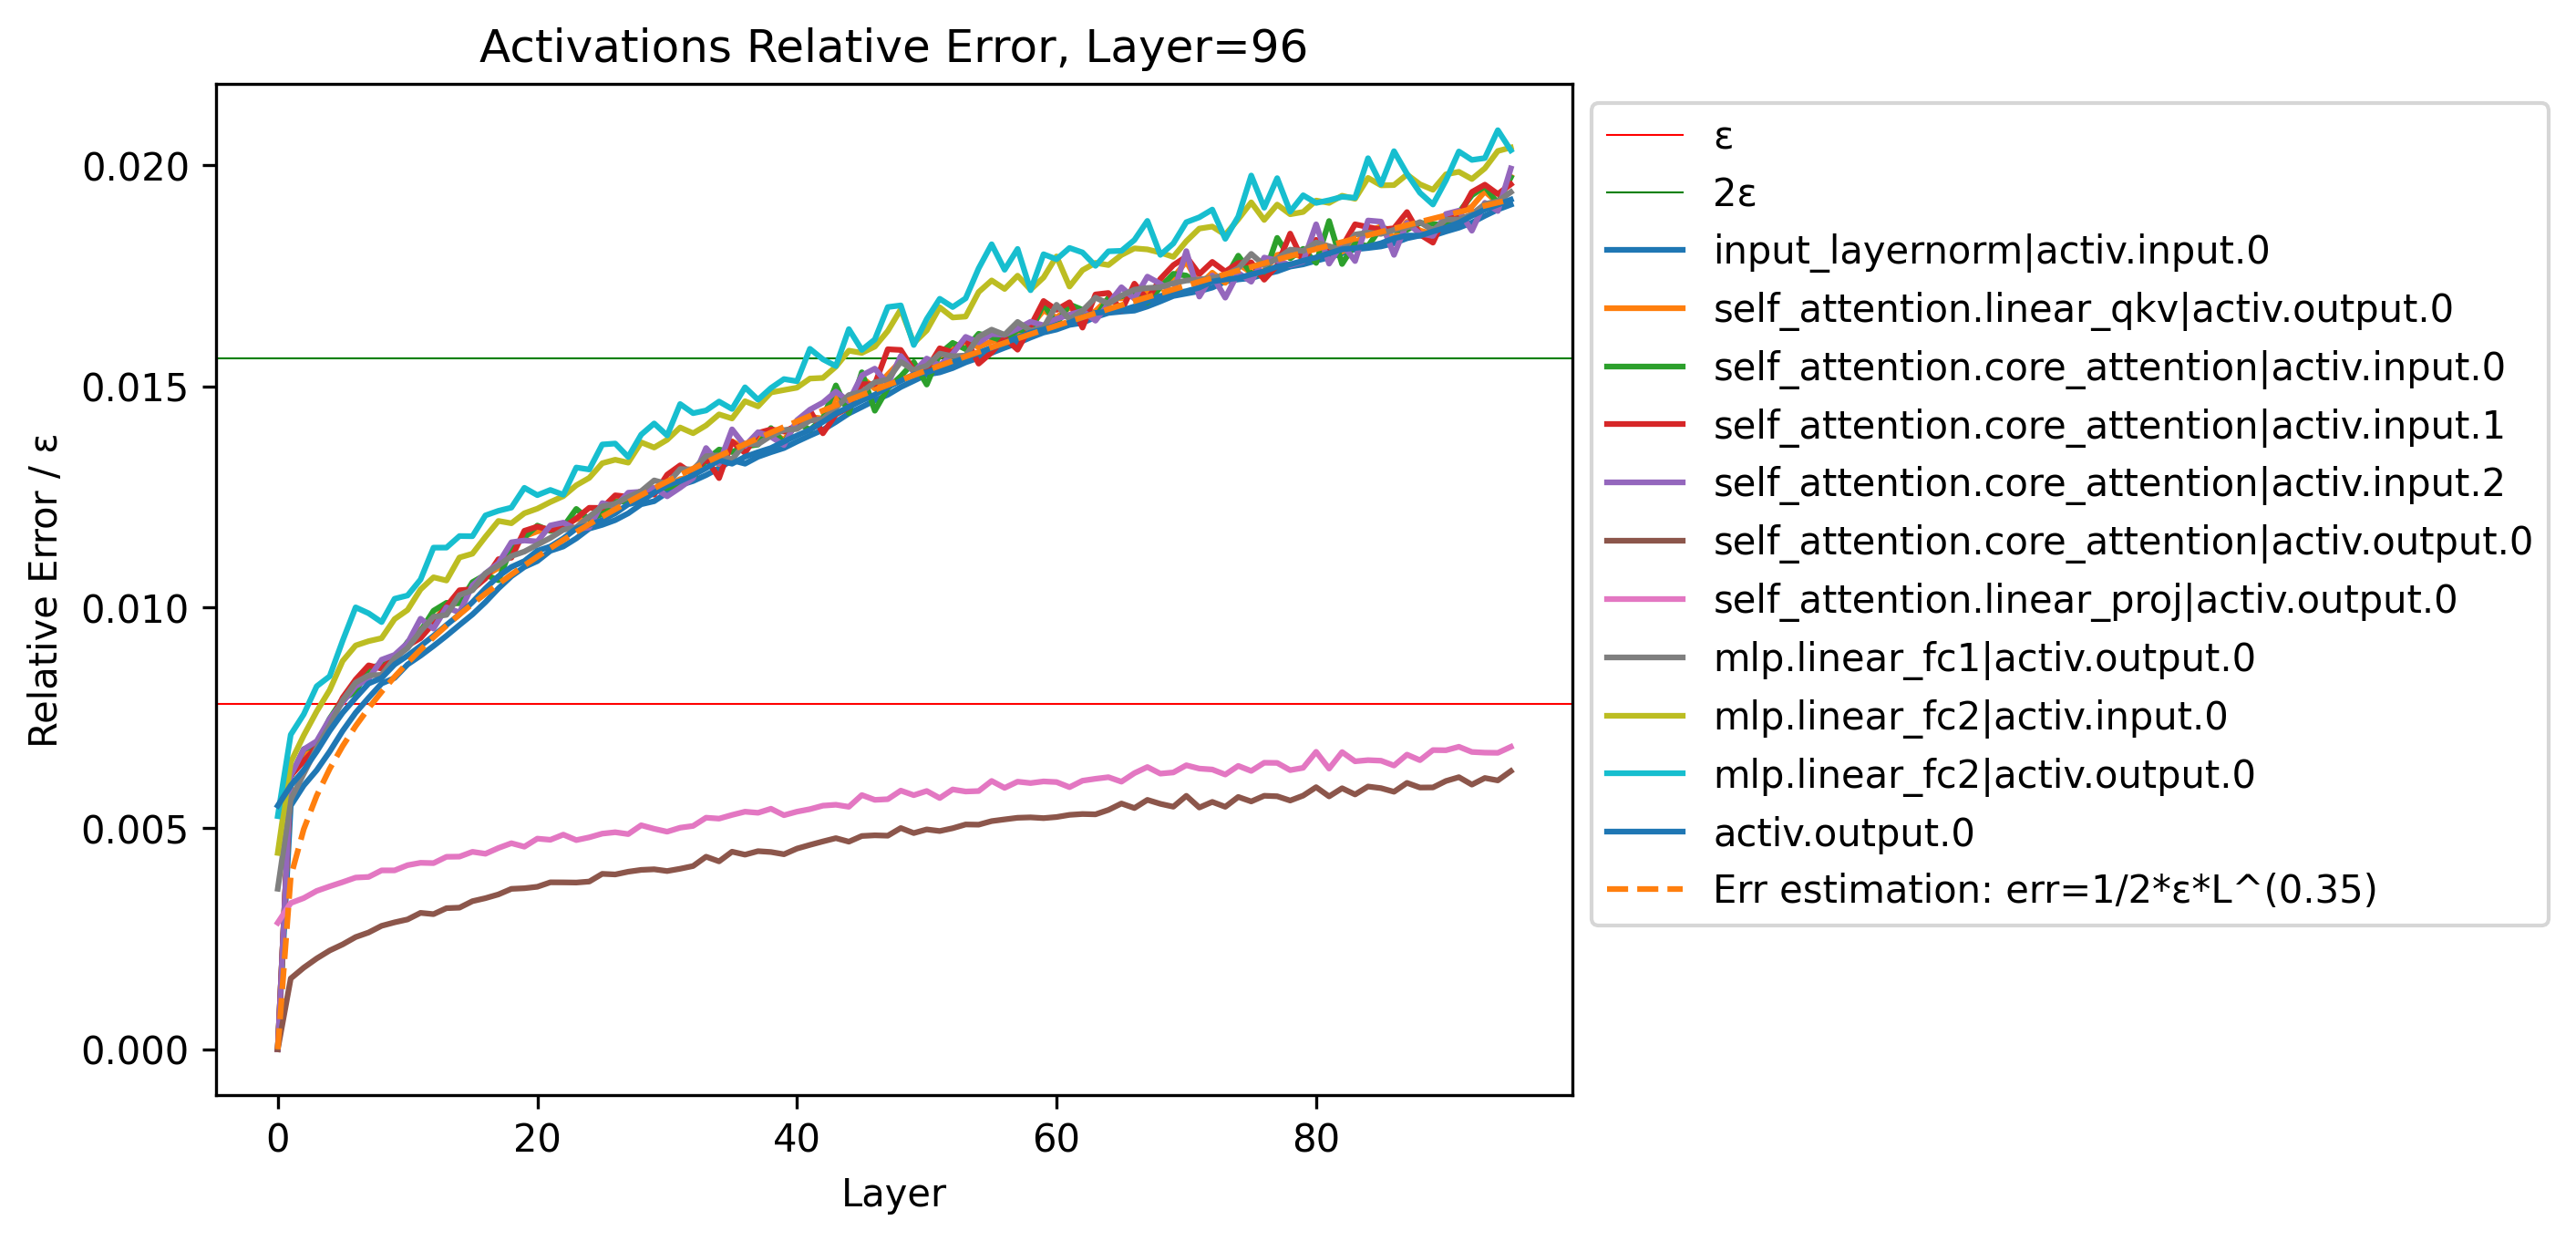

In [ ]:
l = 96
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}-te/activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
label = "Err estimation: err=1/2*ε*L^(0.35)"
plt.plot(range(l), np.maximum(1/2*(bf16)*np.arange(l)**(0.35), 0), label=label, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activations Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

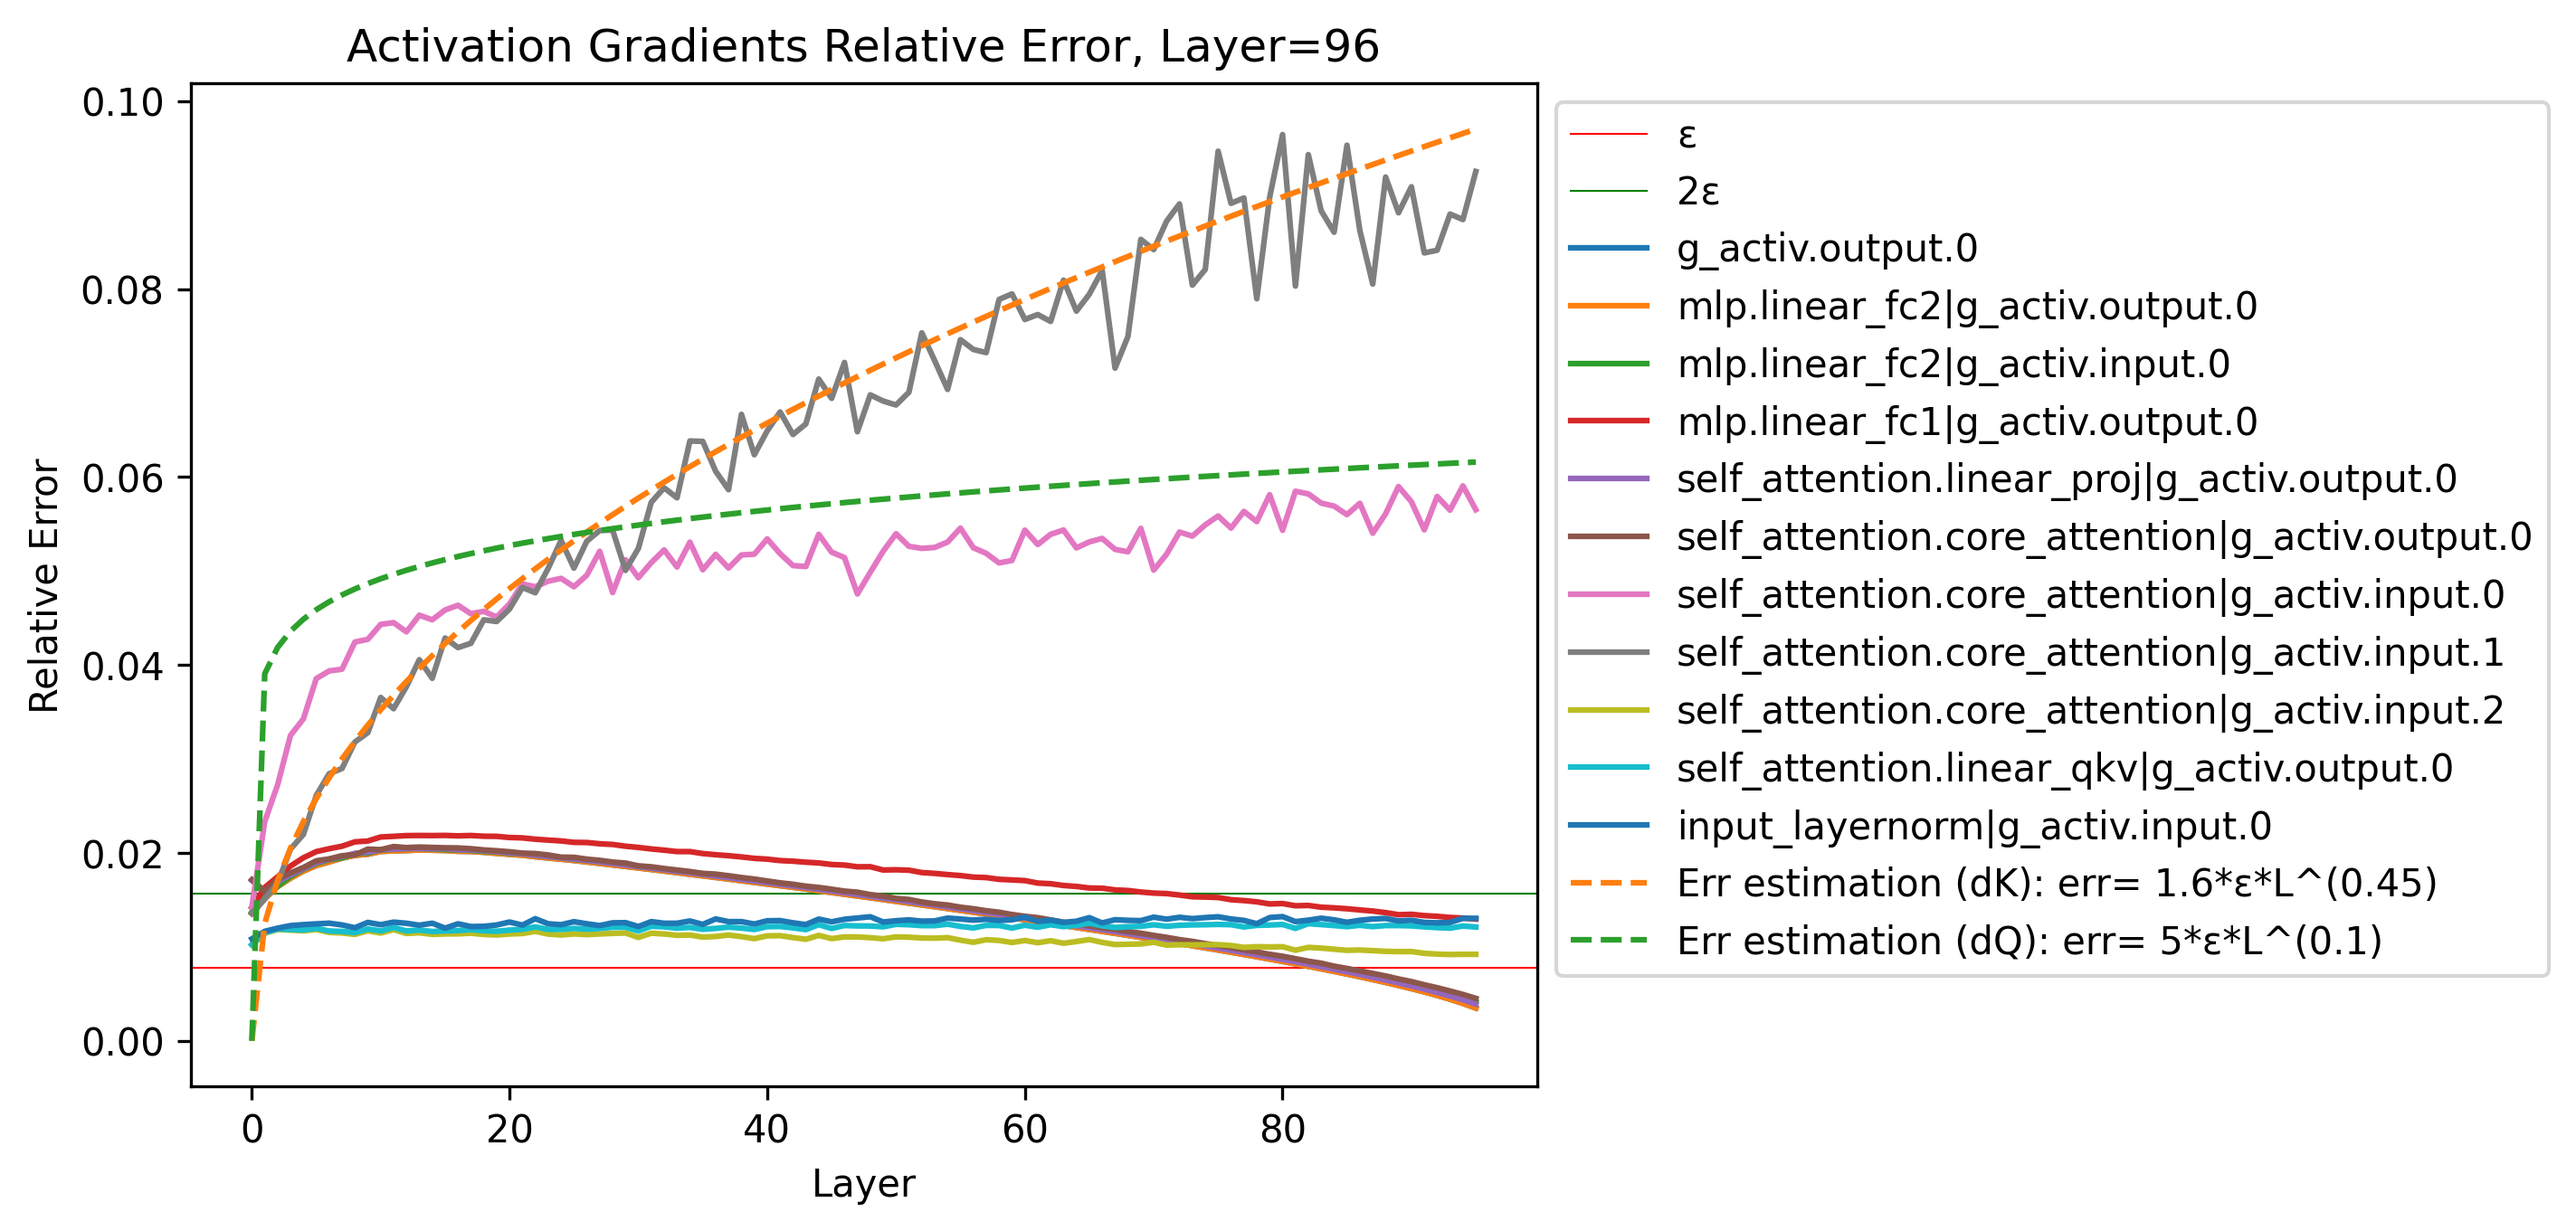

In [ ]:
l = 96
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}-te/g_activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
labelK = "Err estimation (dK): err= 1.6*ε*L^(0.45)"
labelQ = "Err estimation (dQ): err= 5*ε*L^(0.1)"
plt.plot(range(l), 1.6*bf16*np.arange(l)**(0.45), label=labelK, linestyle='--')
plt.plot(range(l), 5*bf16*np.arange(l)**(0.1), label=labelQ, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activation Gradients Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()

# L=128

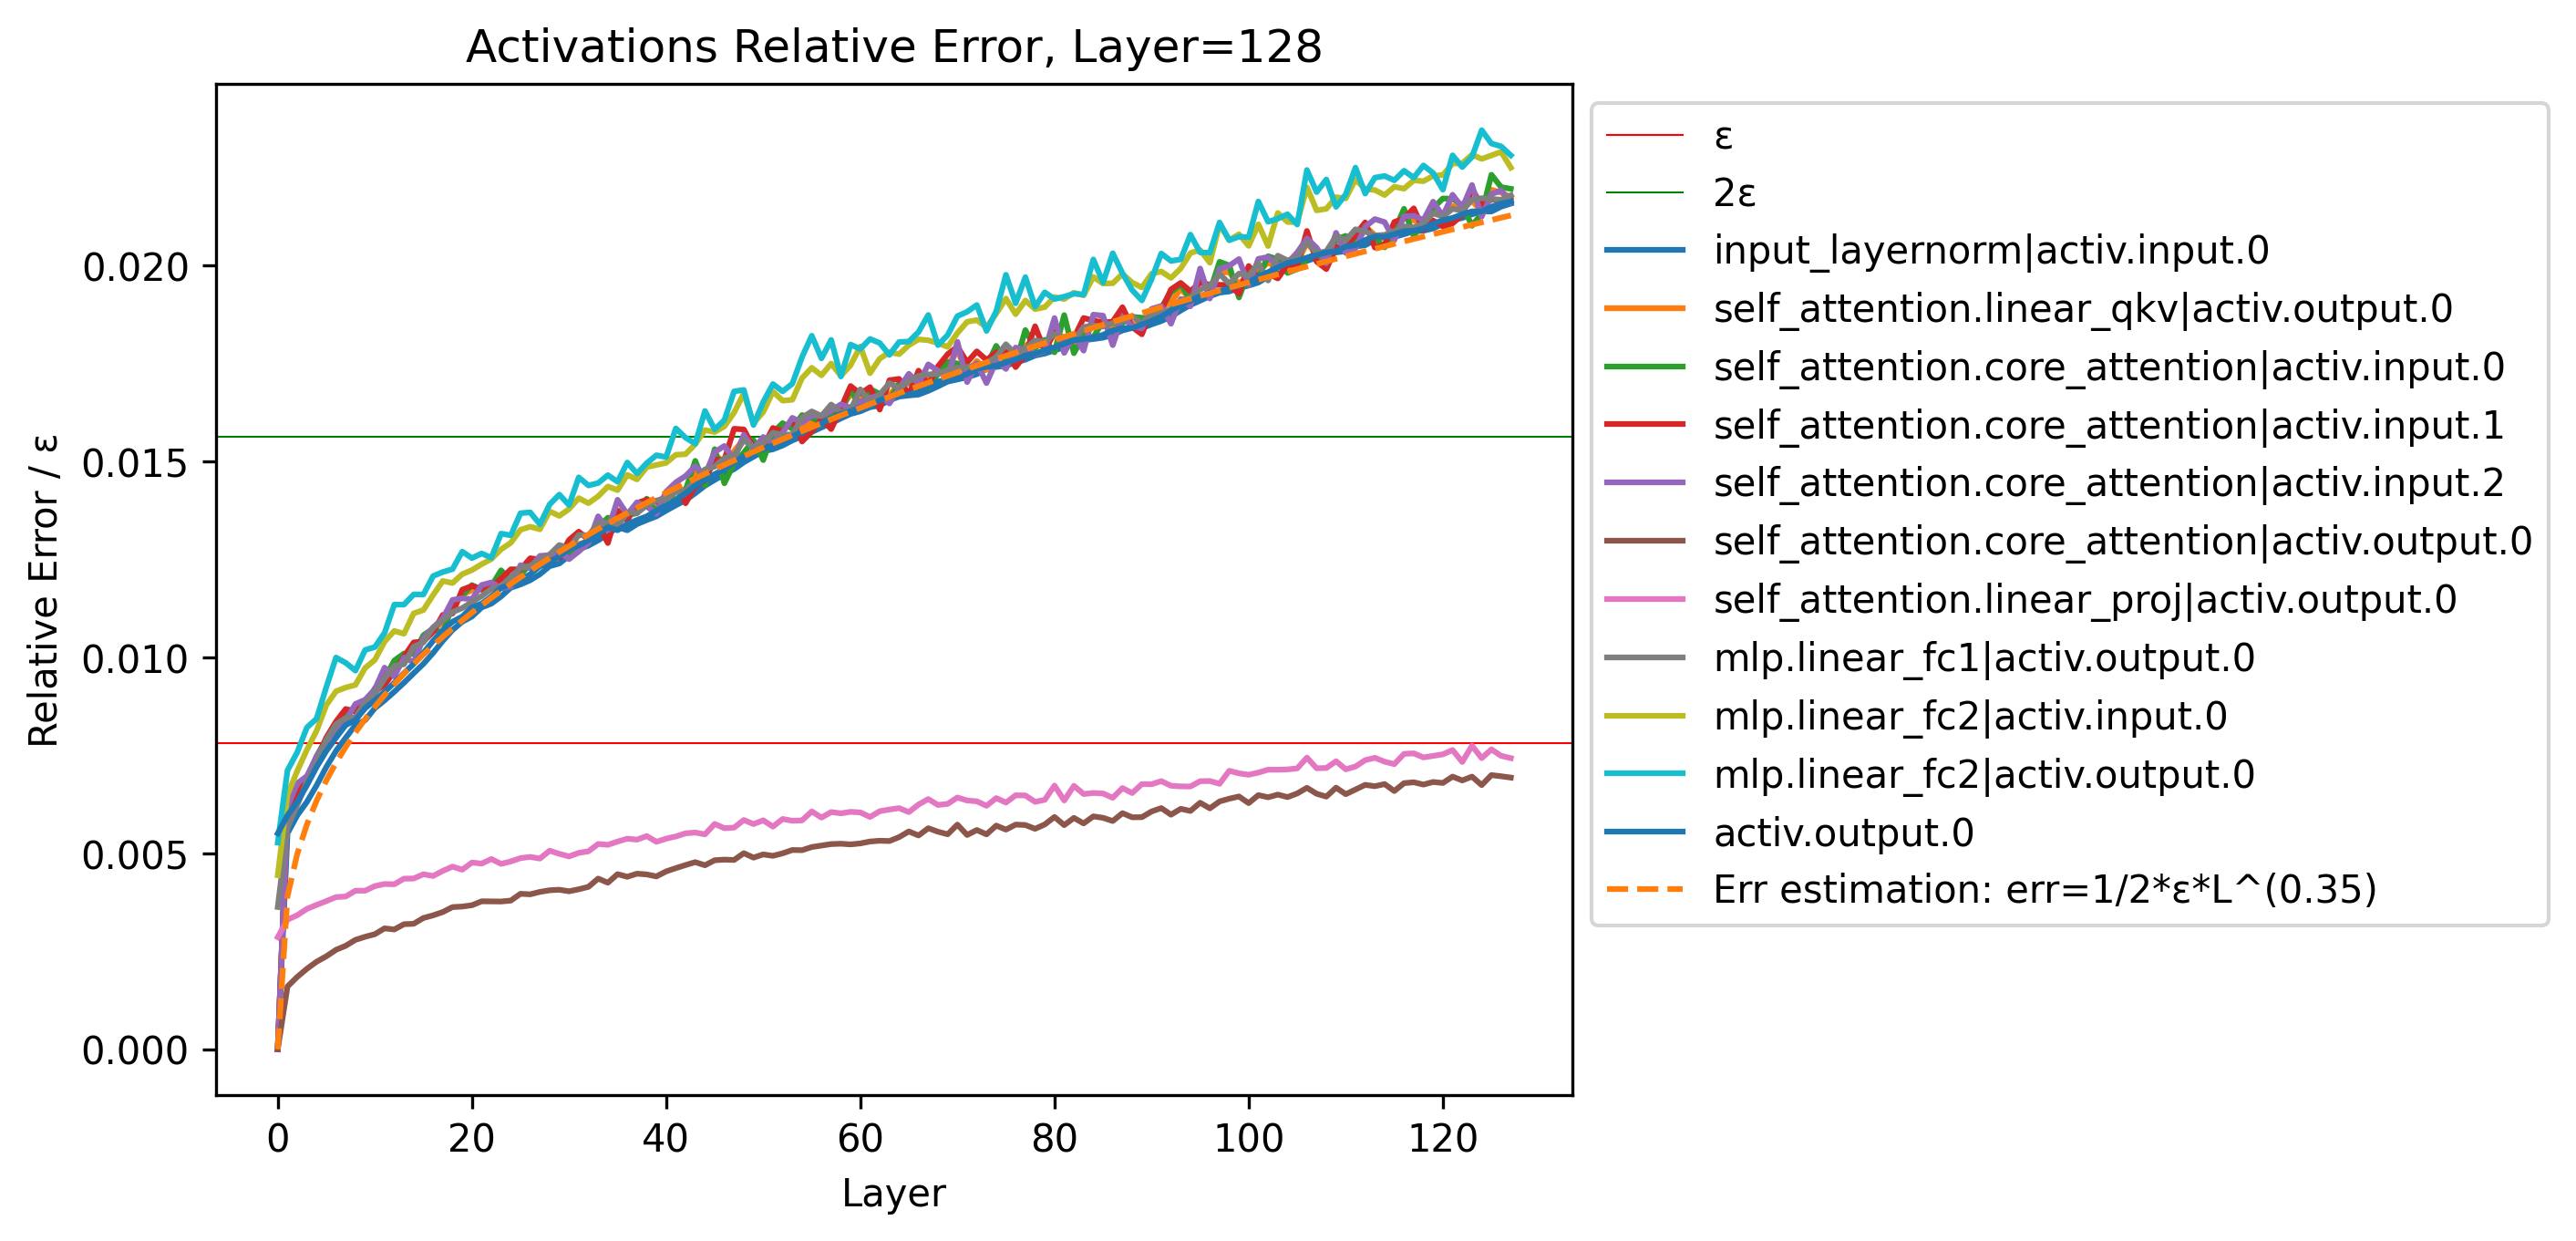

In [ ]:
l = 128
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}-te/activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
label = "Err estimation: err=1/2*ε*L^(0.35)"
plt.plot(range(l), np.maximum(1/2*(bf16)*np.arange(l)**(0.35), 0), label=label, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activations Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()

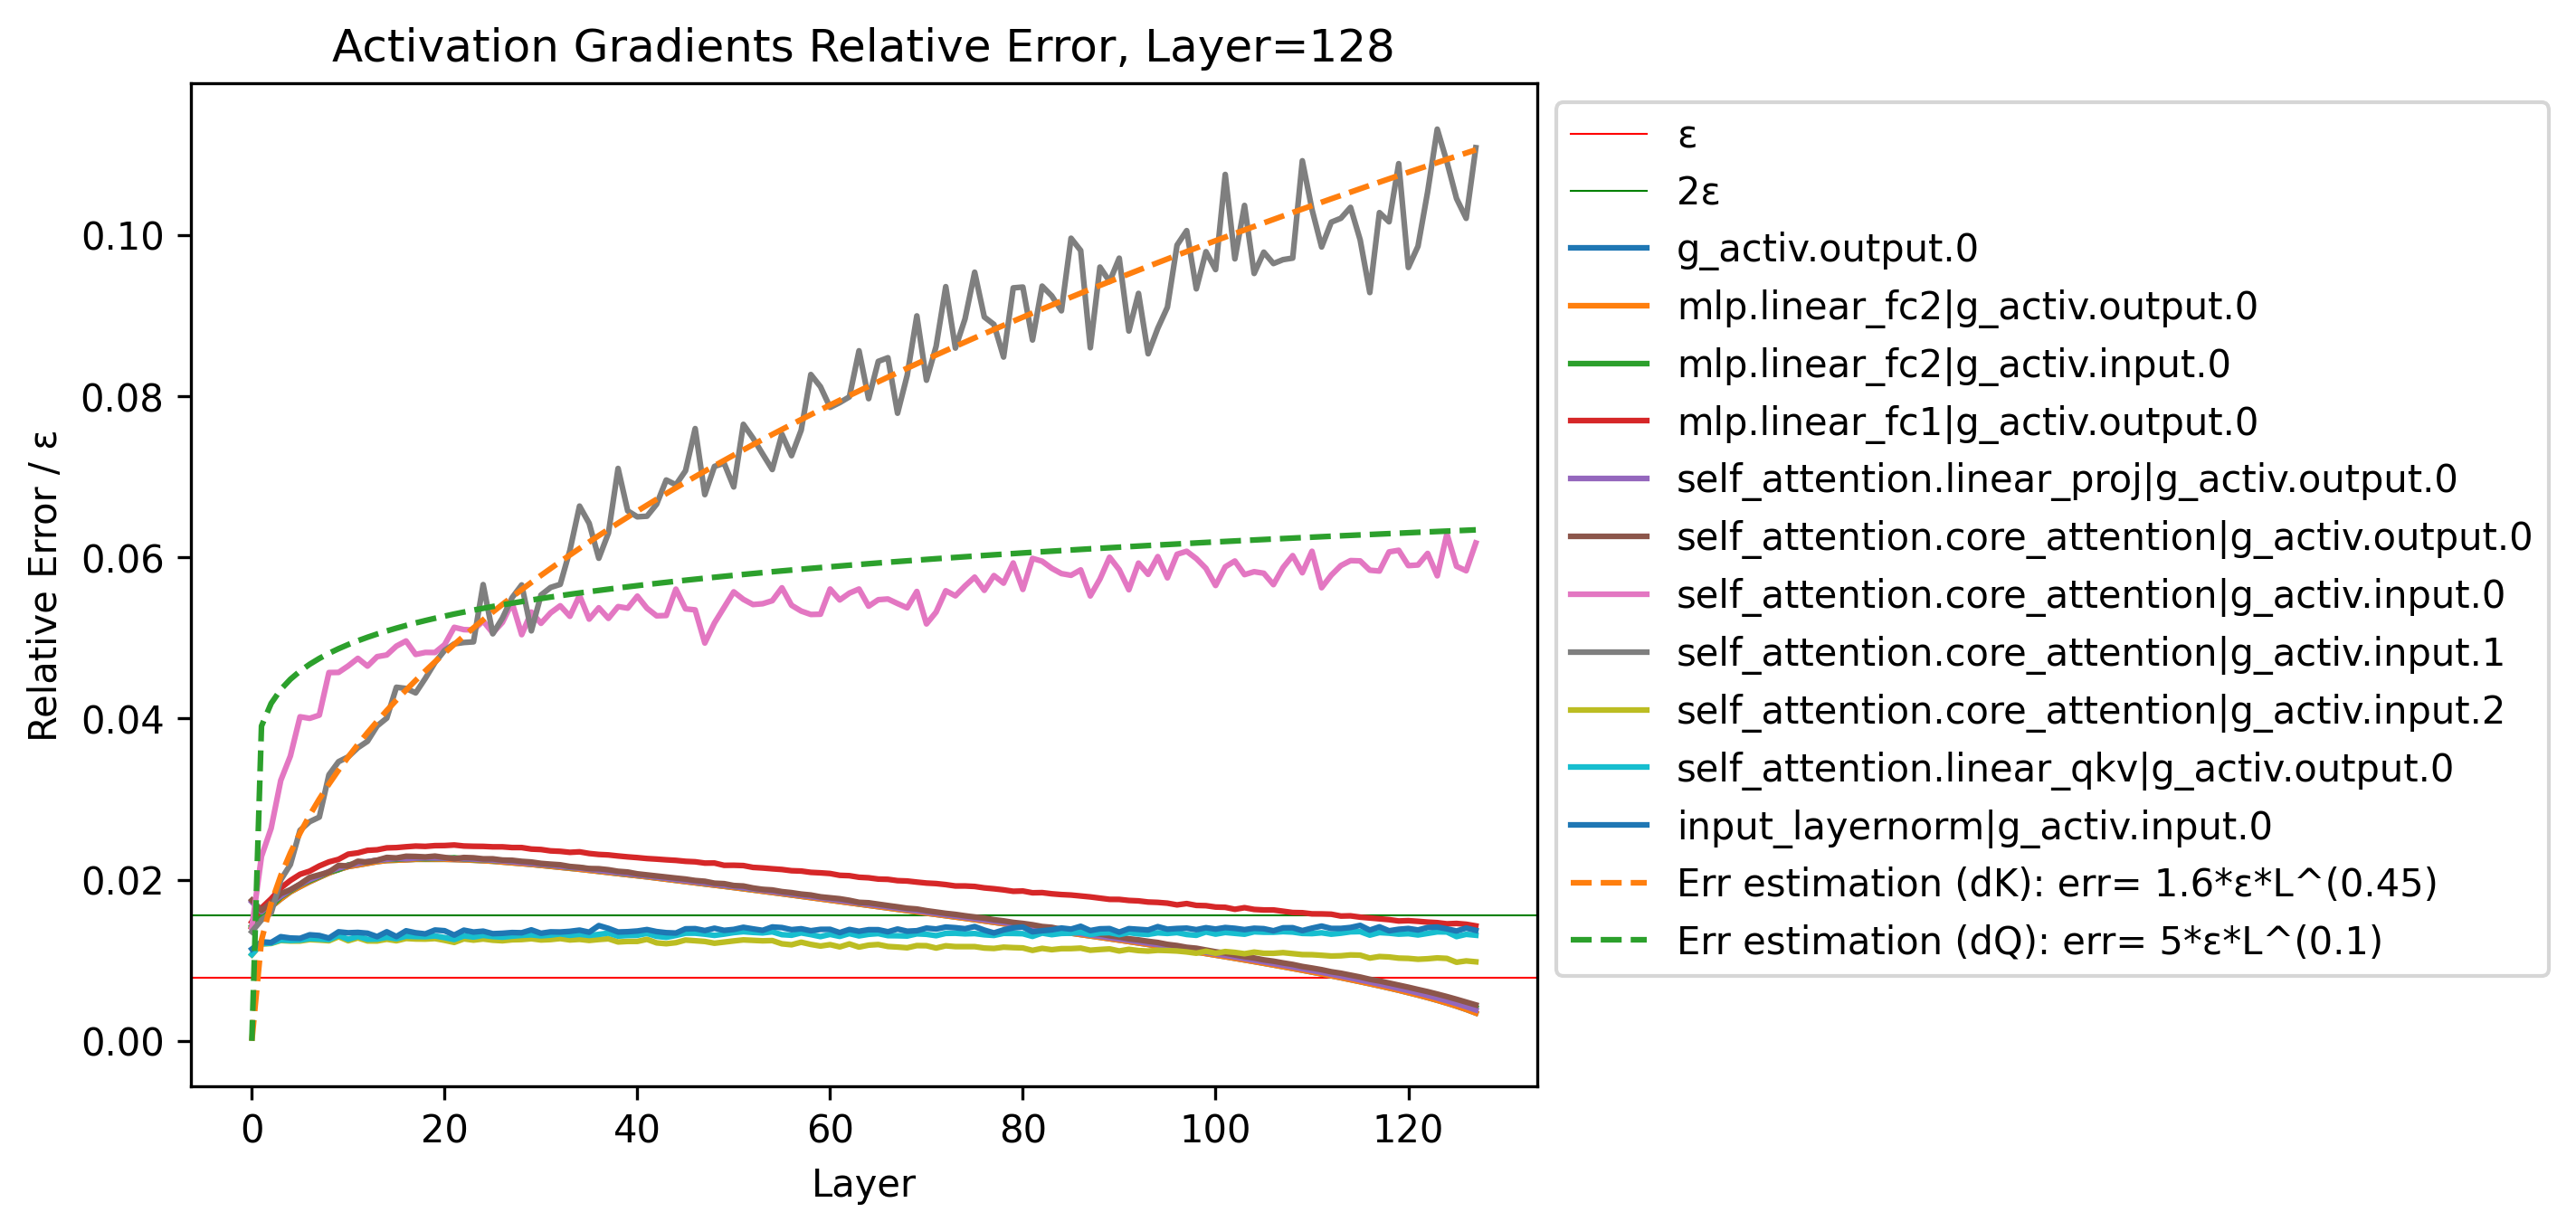

In [ ]:
l = 128
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}-te/g_activ.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
labelK = "Err estimation (dK): err= 1.6*ε*L^(0.45)"
labelQ = "Err estimation (dQ): err= 5*ε*L^(0.1)"
plt.plot(range(128), 1.6*bf16*np.arange(128)**(0.45), label=labelK, linestyle='--')
plt.plot(range(128), 5*bf16*np.arange(128)**(0.1), label=labelQ, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activation Gradients Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

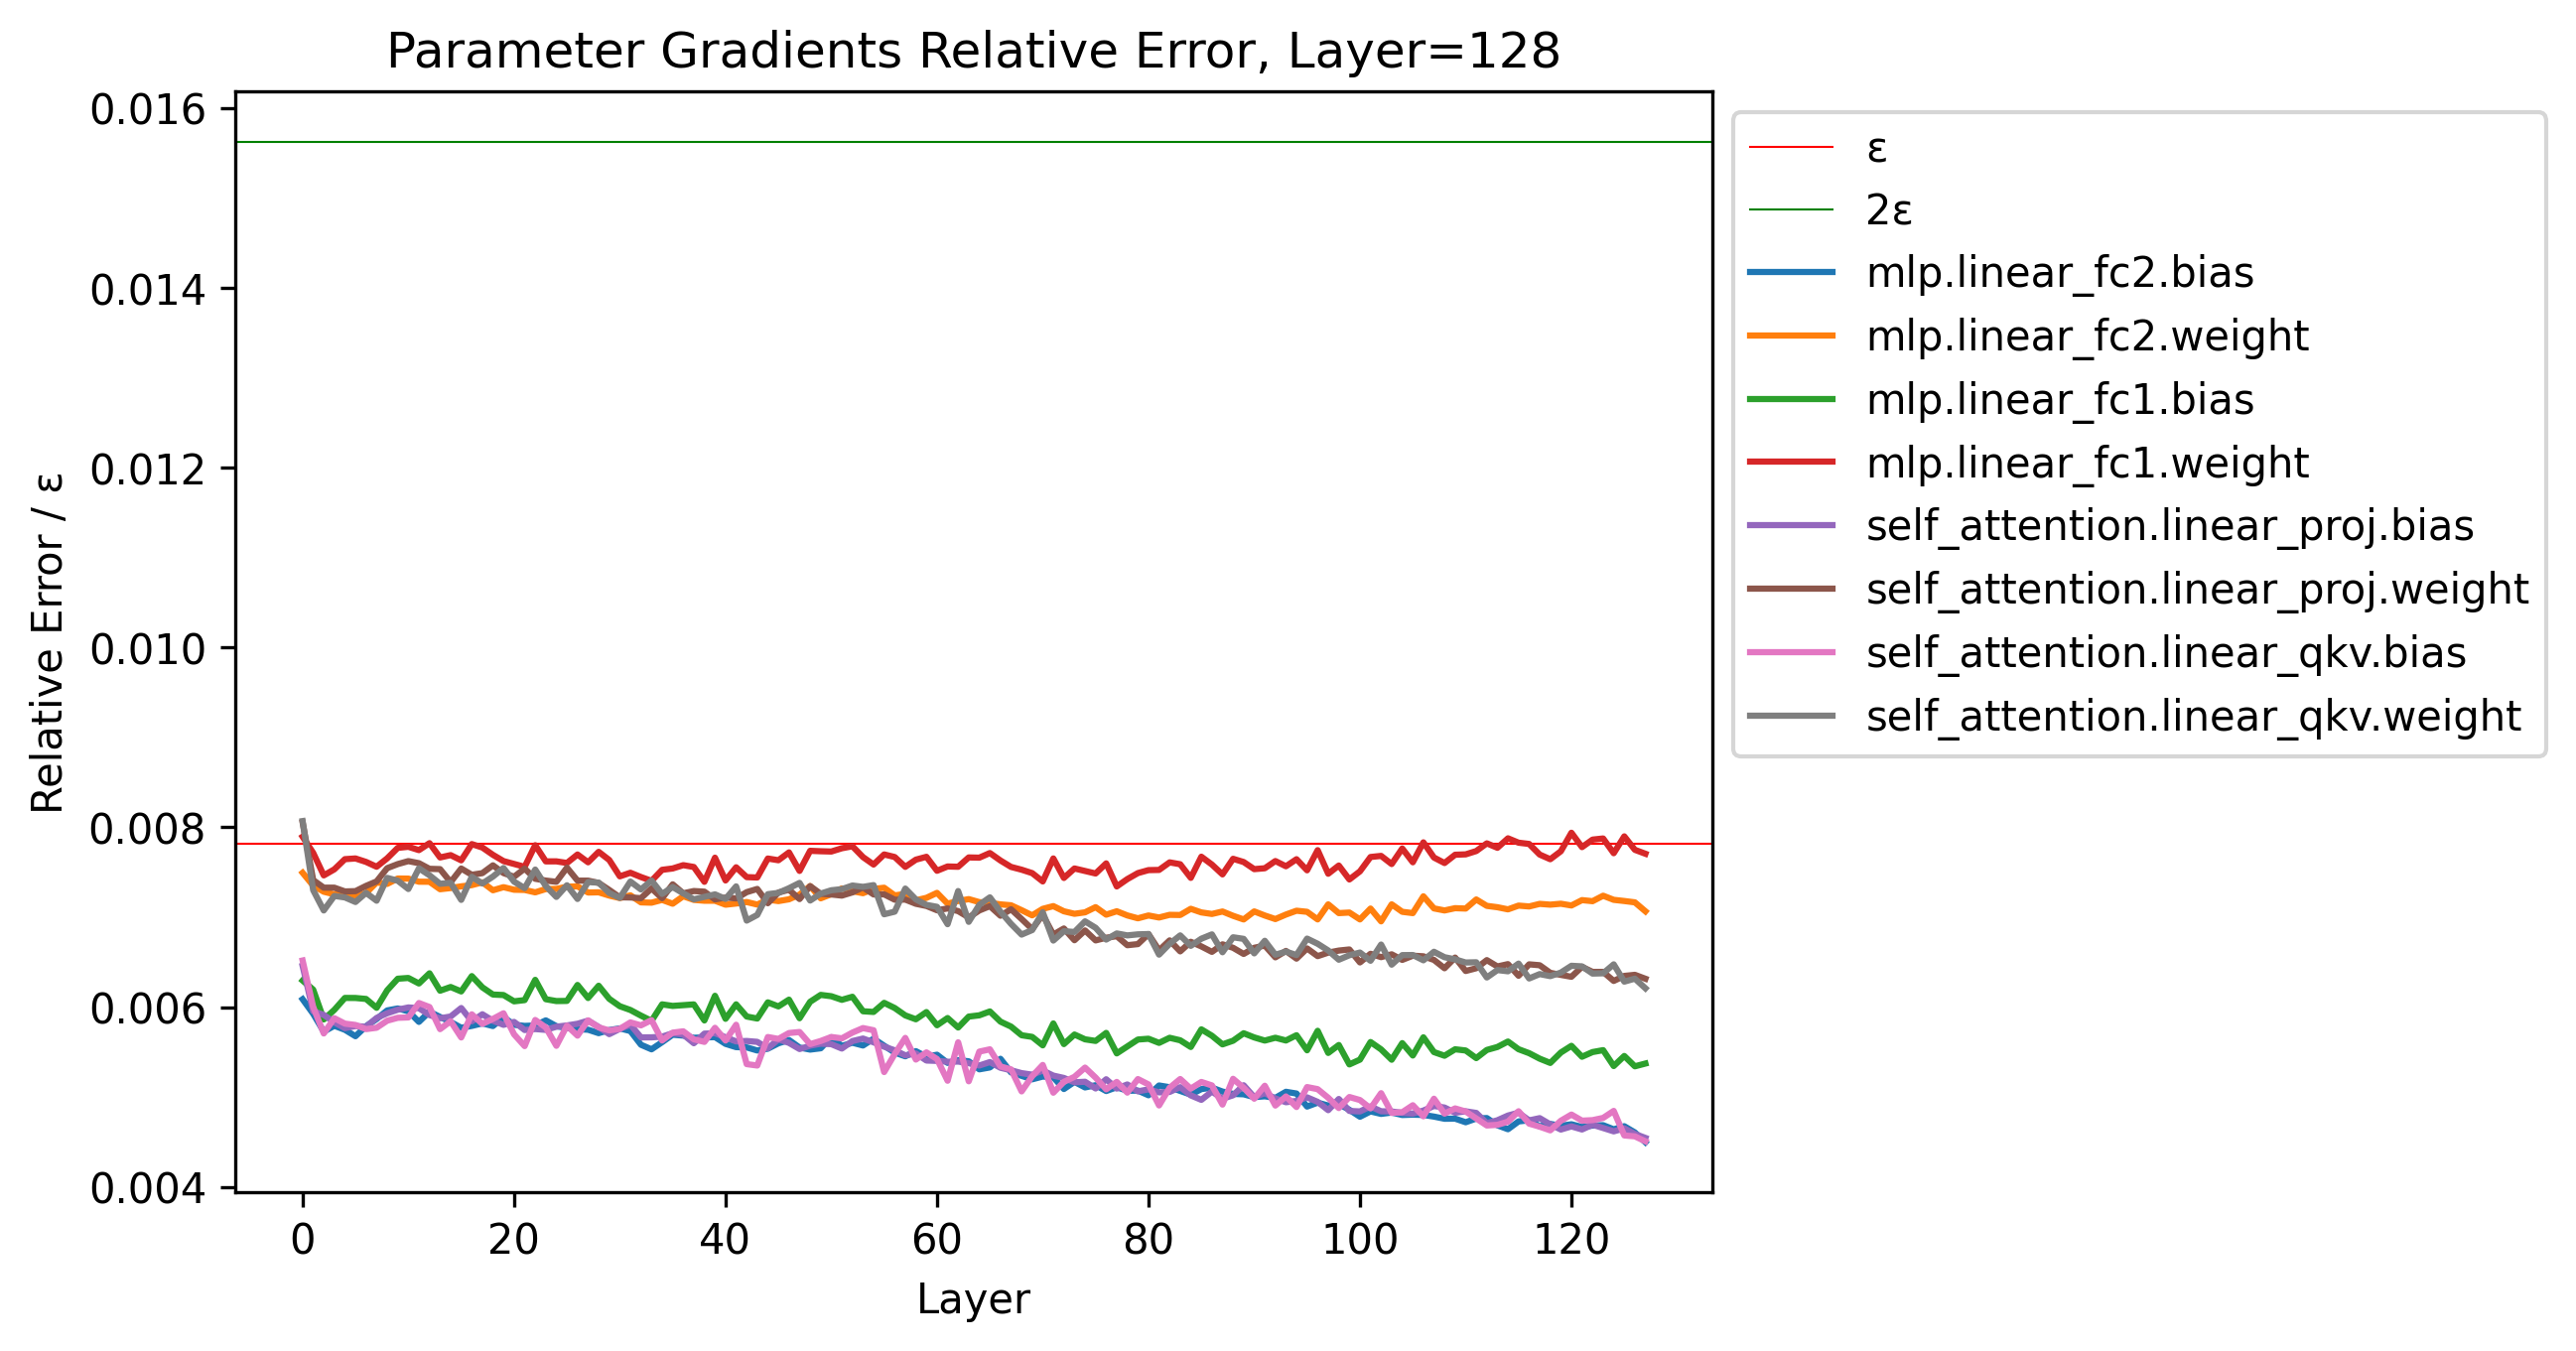

In [ ]:
l = 128
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp2--l{l}-te/g_param.pt"), 4, l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=bf16, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr.mean(axis=0), label=k)
label = "Err estimation: err=1/2*ε*L^(0.35)"
# plt.plot(range(l), np.maximum(1/2*(bf16)*np.arange(l)**(0.35), 0), label=label, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Parameter Gradients Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

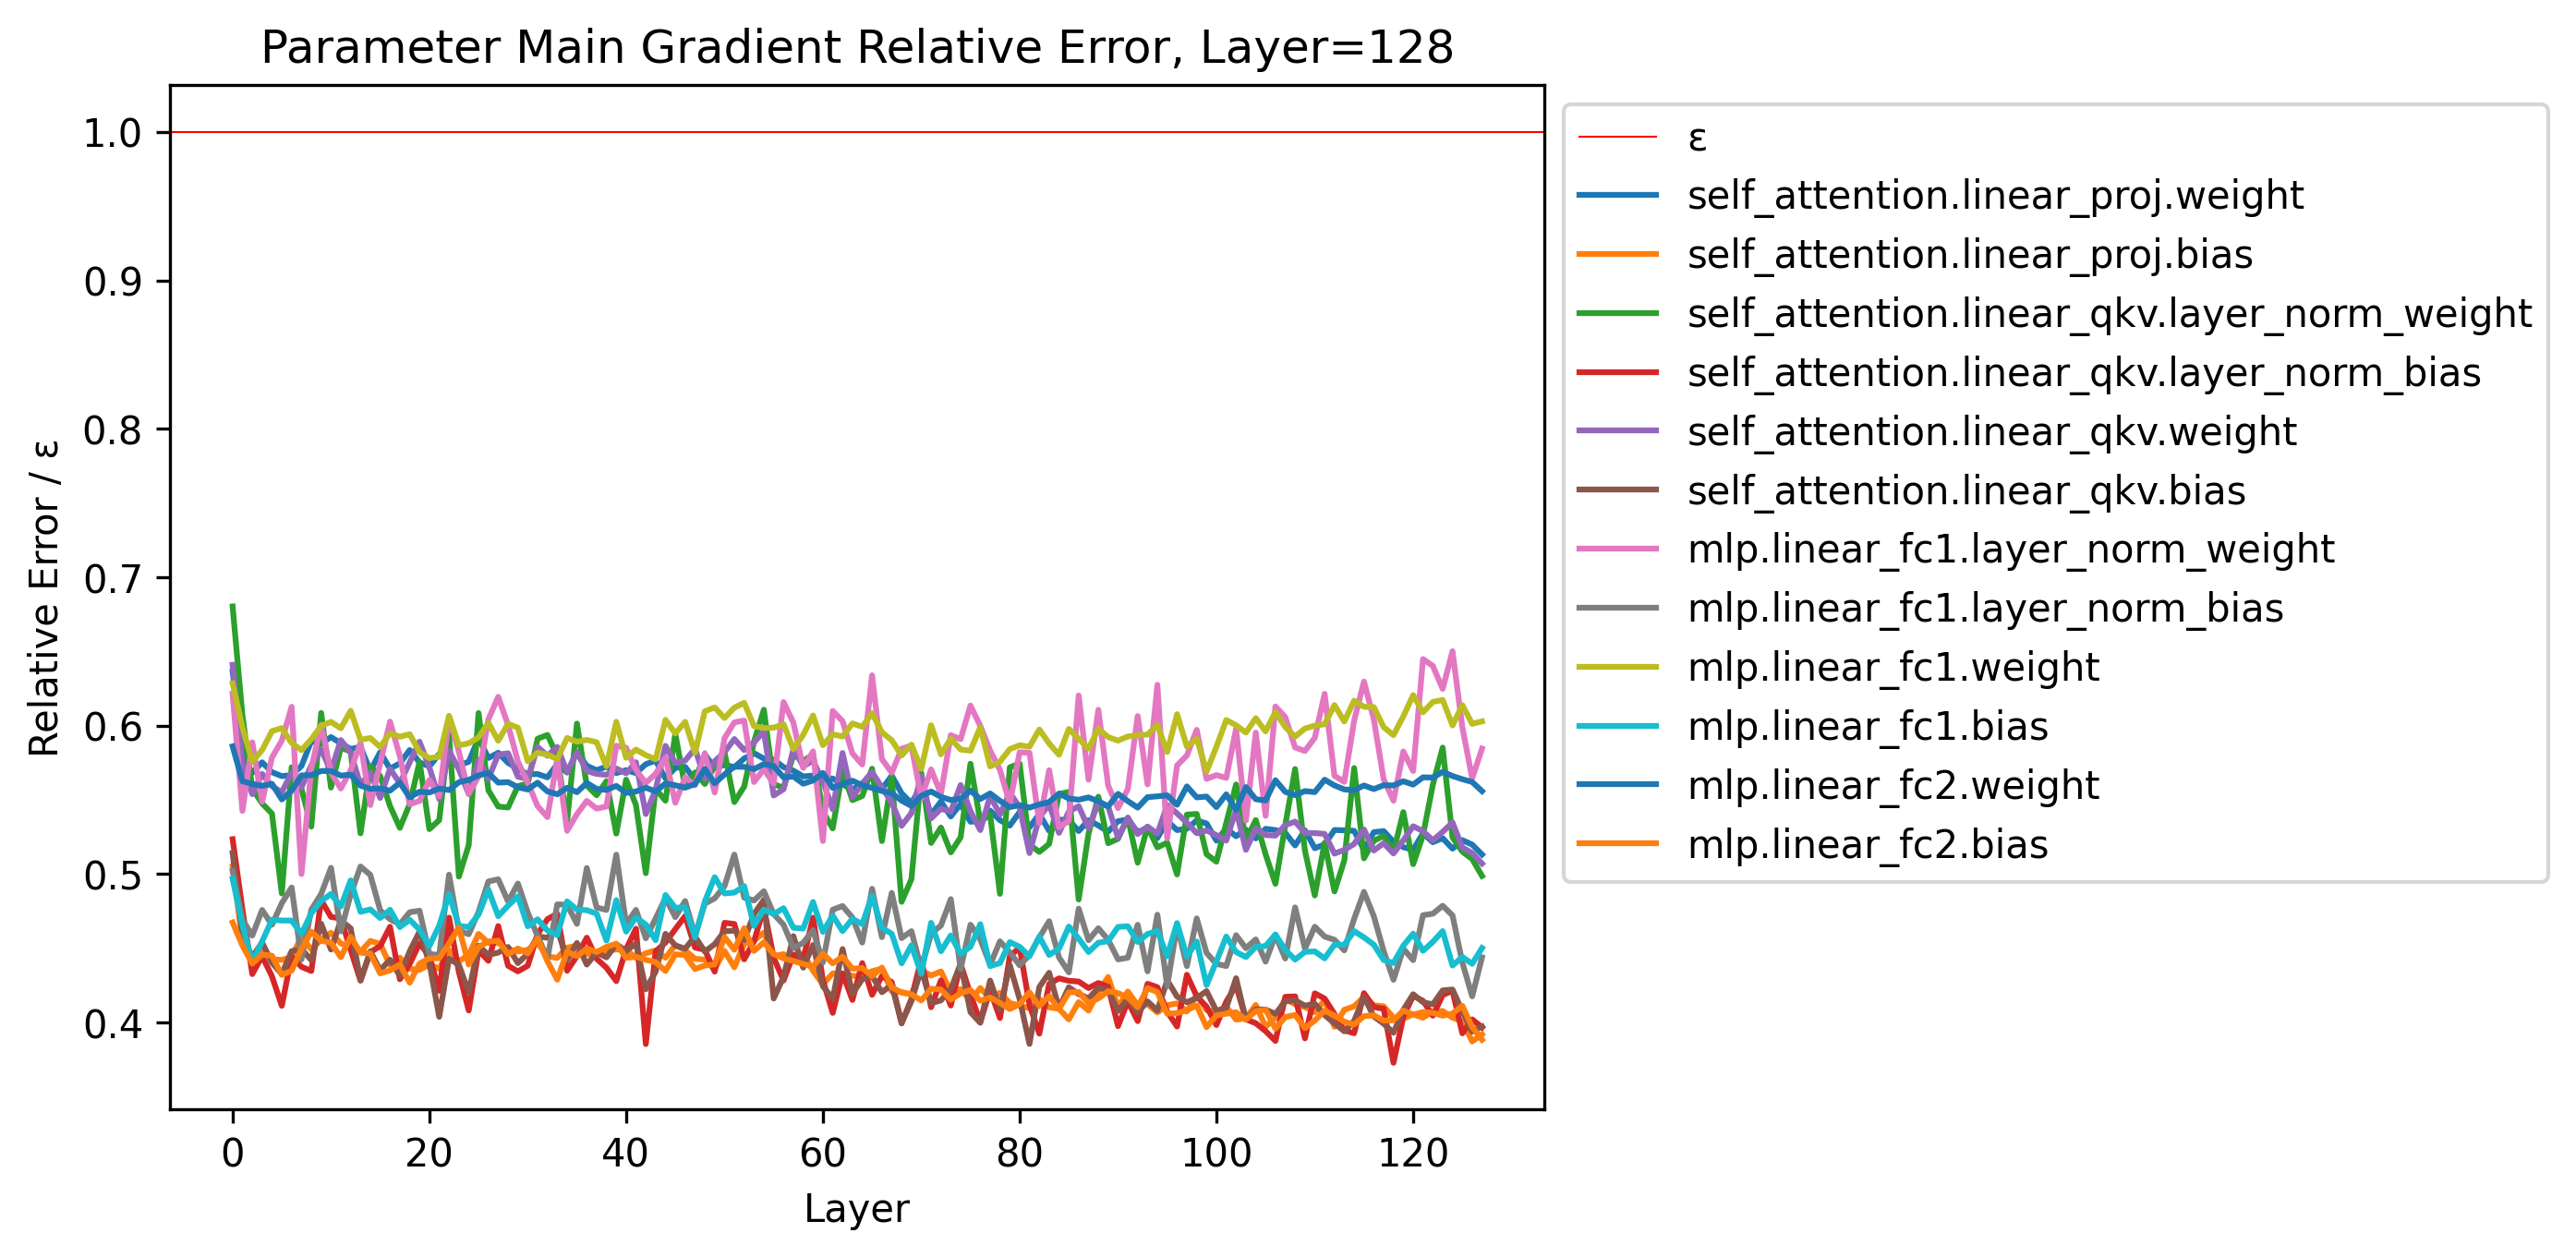

In [ ]:
l = 128
err_arr = get_err_array_main(torch.load(neckruns/f"_single-v-tp2--l{l}-te/g_param_main.pt"), l)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=1, color='r', linestyle='-', linewidth=0.5, label='ε')
for k, rerr in err_arr.items():
    plt.plot(range(l), rerr/bf16, label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Parameter Main Gradient Relative Error, Layer={l}")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

0.44645773834863073 -4.377648317302329


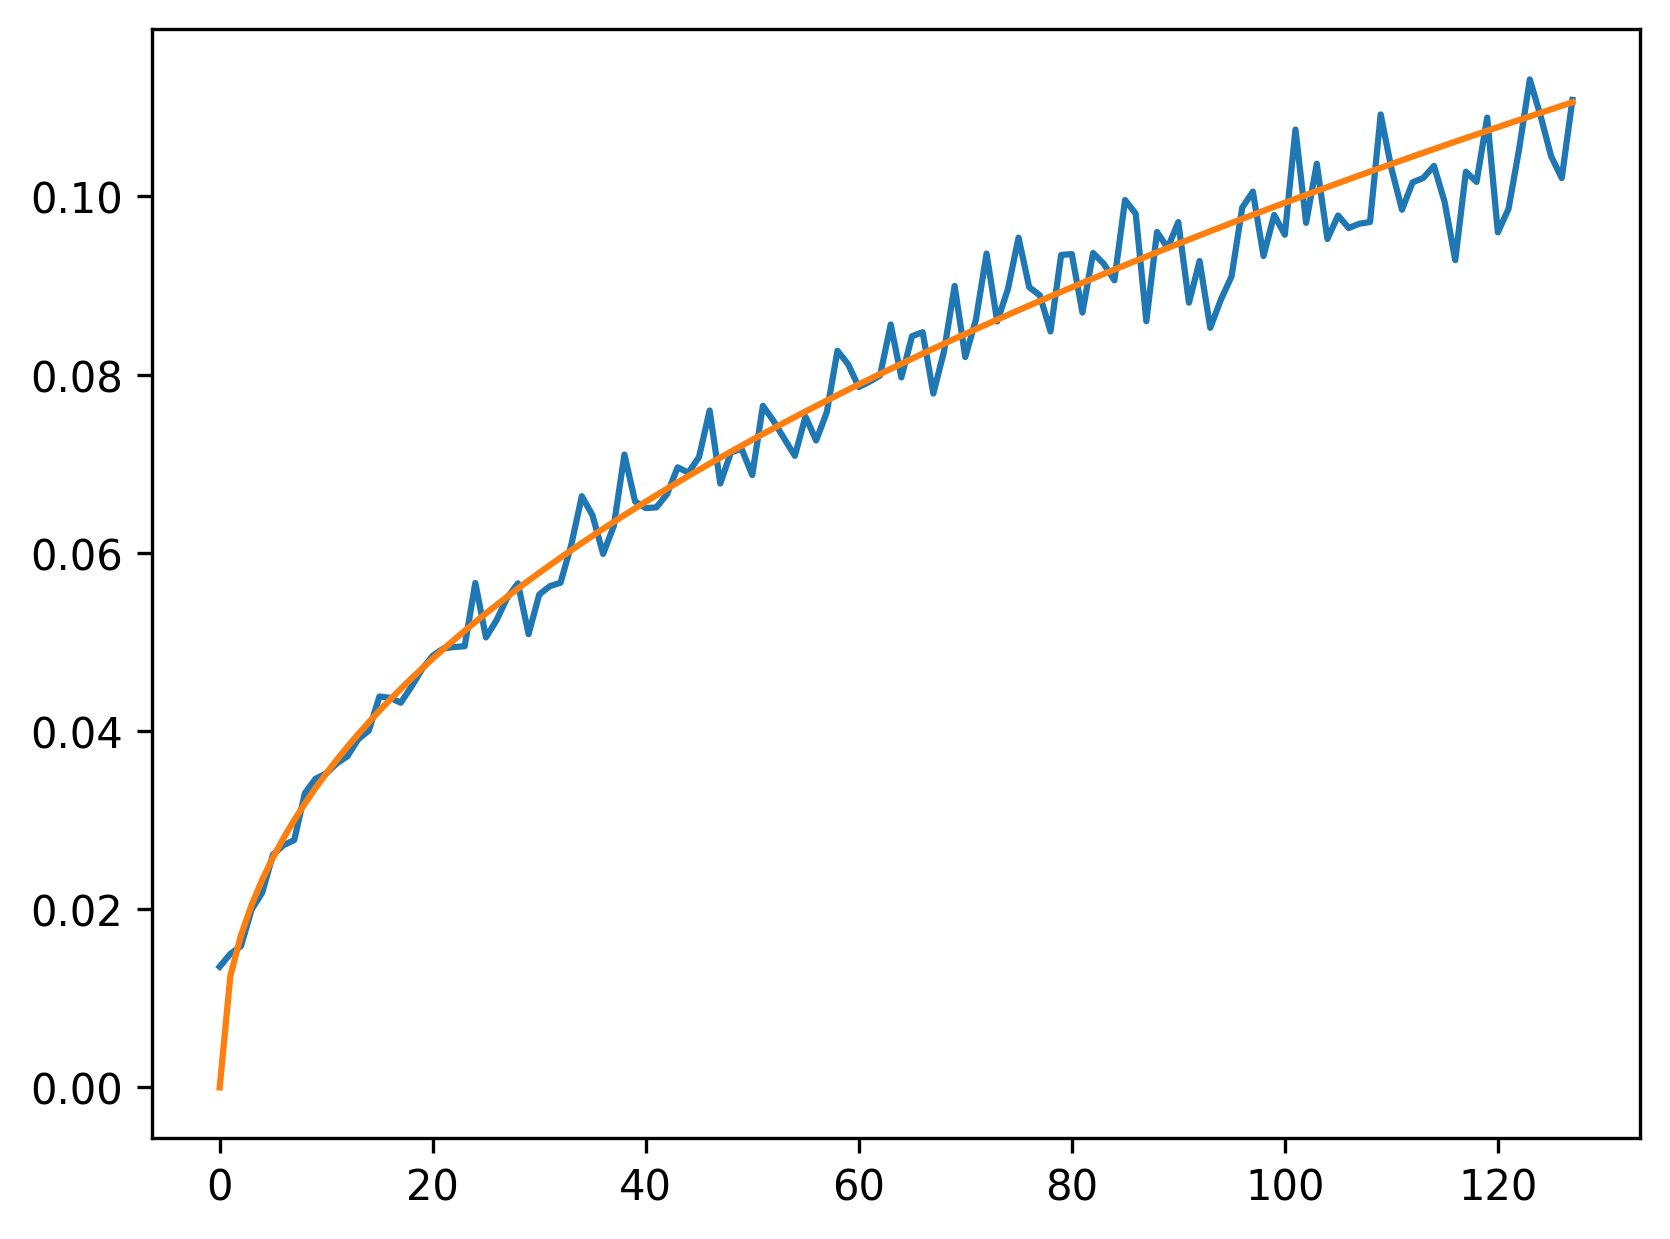

In [25]:
dK = err_arr["self_attention.core_attention|g_activ.input.1"].mean(axis=0)
plt.plot(range(128), dK)

log_x = np.log(np.arange(3, 128))
log_y = np.log(dK[3:])
a, log_C = np.polyfit(log_x, log_y, 1)
print(a, log_C)

plt.plot(range(128), 1.6*bf16*np.arange(128)**(0.45))

# plt.xscale('log')
# plt.yscale('log')
plt.show()

In [23]:
np.exp(log_C) / 2**-7

1.6070206659309738

0.09714536729537314 -3.2902096304137887


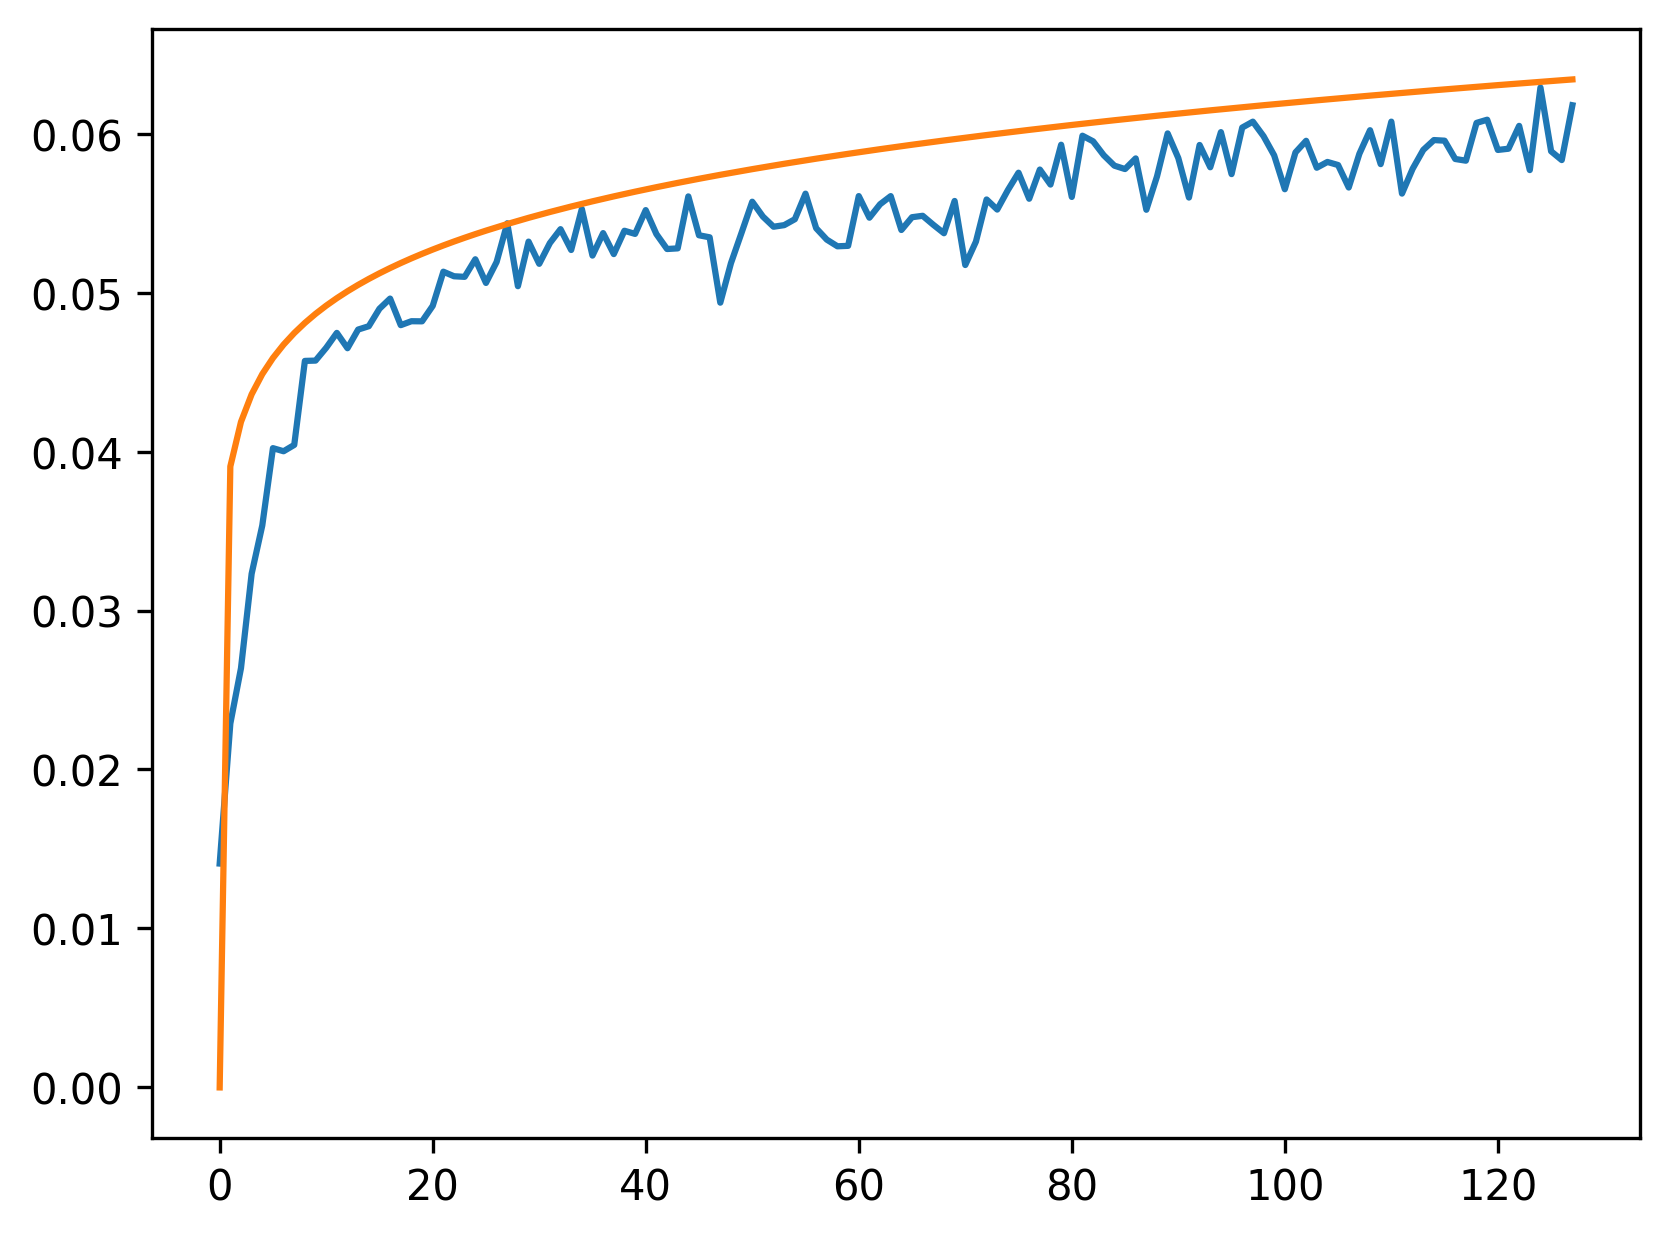

In [32]:
dQ = err_arr["self_attention.core_attention|g_activ.input.0"].mean(axis=0)
plt.plot(range(128), dQ)

log_x = np.log(np.arange(10, 128))
log_y = np.log(dQ[10:])
a, log_C = np.polyfit(log_x, log_y, 1)
print(a, log_C)

plt.plot(range(128), 5*bf16*np.arange(128)**(0.1))

# plt.xscale('log')
# plt.yscale('log')
plt.show()

In [30]:
np.exp(log_C) / 2**-7

4.767493206381184